In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("WarehouseFlow EDA environment ready.")


WarehouseFlow EDA environment ready.


In [4]:
movements = pd.read_csv(
    "../01_Raw_Data/stock_movements.csv"
)

requests = pd.read_csv(
    "../01_Raw_Data/movement_requests.csv"
)

inventory = pd.read_csv(
    "../01_Raw_Data/inventory_snapshot.csv"
)

sku = pd.read_csv(
    "../01_Raw_Data/dim_sku.csv"
)

locations = pd.read_csv(
    "../01_Raw_Data/dim_location.csv"
)

In [5]:
print("Movements :", movements.shape)
print("Requests  :", requests.shape)
print("Inventory :", inventory.shape)
print("SKU       :", sku.shape)
print("Locations :", locations.shape)

Movements : (66425, 14)
Requests  : (50000, 7)
Inventory : (180000, 6)
SKU       : (10000, 8)
Locations : (28000, 6)


In [6]:
movements.head()

,Movement_ID,Request_ID,Requested_Timestamp,Completed_Timestamp,SKU_ID,From_Location,To_Location,From_Area,To_Area,Quantity,Movement_Type,Priority,Status,Completed_By
0,MOV0000001,REQ000001,2025-10-13 18:43:00,2025-10-13 23:29:21.908184189,SKU08696,SCR-030,BI-15868,Screening,Racking,28,PUTAWAY,Normal,COMPLETED,Stock Team C
1,MOV0000002,REQ000001,2025-10-13 15:37:00,2025-10-13 16:12:10.597445199,SKU09231,SCR-025,PA-01304,Screening,Racking,33,PUTAWAY,Normal,COMPLETED,Stock Team C
2,MOV0000003,REQ000002,2026-08-24 16:26:00,2026-08-24 19:02:52.294998020,SKU09968,SCR-003,REP-025,Screening,Repair,6,DEPARTMENT_TRANSFER,Normal,COMPLETED,Stock Team D
3,MOV0000004,REQ000002,2026-08-24 11:33:00,2026-08-24 17:34:11.528321160,SKU04376,SCR-010,REP-016,Screening,Repair,24,DEPARTMENT_TRANSFER,Normal,COMPLETED,Stock Team C
4,MOV0000005,REQ000003,2025-10-06 17:30:00,2025-10-06 18:23:19.647695061,SKU06808,SCR-040,REP-040,Screening,Repair,27,DEPARTMENT_TRANSFER,High,COMPLETED,Stock Team A


In [7]:
movements.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66425 entries, 0 to 66424
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Movement_ID          66425 non-null  object
 1   Request_ID           66425 non-null  object
 2   Requested_Timestamp  66425 non-null  object
 3   Completed_Timestamp  57061 non-null  object
 4   SKU_ID               66425 non-null  object
 5   From_Location        66425 non-null  object
 6   To_Location          66425 non-null  object
 7   From_Area            66425 non-null  object
 8   To_Area              66425 non-null  object
 9   Quantity             66425 non-null  int64 
 10  Movement_Type        66425 non-null  object
 11  Priority             66425 non-null  object
 12  Status               66425 non-null  object
 13  Completed_By         57061 non-null  object
dtypes: int64(1), object(13)
memory usage: 7.1+ MB


In [8]:
movements.isnull().sum()

Movement_ID               0
Request_ID                0
Requested_Timestamp       0
Completed_Timestamp    9364
SKU_ID                    0
From_Location             0
To_Location               0
From_Area                 0
To_Area                   0
Quantity                  0
Movement_Type             0
Priority                  0
Status                    0
Completed_By           9364
dtype: int64

In [9]:
movements["Requested_Timestamp"] = pd.to_datetime(
    movements["Requested_Timestamp"]
)

movements["Completed_Timestamp"] = pd.to_datetime(
    movements["Completed_Timestamp"]
)

In [10]:
movements[
    ["Requested_Timestamp", "Completed_Timestamp"]
].dtypes

Requested_Timestamp    datetime64[ns]
Completed_Timestamp    datetime64[ns]
dtype: object

In [11]:
movements["Processing_Minutes"] = (
    movements["Completed_Timestamp"]
    - movements["Requested_Timestamp"]
).dt.total_seconds() / 60

In [12]:
movements["Processing_Minutes"].describe()

count    57061.000000
mean       236.071899
std        159.510928
min         12.000000
25%        118.311038
50%        201.337785
75%        317.142407
max       1440.000000
Name: Processing_Minutes, dtype: float64

In [13]:
total_movements = len(movements)

completed_movements = (
    movements["Status"] == "COMPLETED"
).sum()

open_movements = total_movements - completed_movements

completion_rate = (
    completed_movements / total_movements
) * 100

total_units = movements["Quantity"].sum()

print("Total movements       :", total_movements)
print("Completed movements   :", completed_movements)
print("Open movements        :", open_movements)
print("Completion rate       :", round(completion_rate, 2), "%")
print("Total units moved     :", total_units)

Total movements       : 66425
Completed movements   : 57061
Open movements        : 9364
Completion rate       : 85.9 %
Total units moved     : 2286527


In [14]:
status_counts = movements["Status"].value_counts()

status_counts

Status
COMPLETED      57061
PENDING         5409
IN_PROGRESS     2995
CANCELLED        960
Name: count, dtype: int64

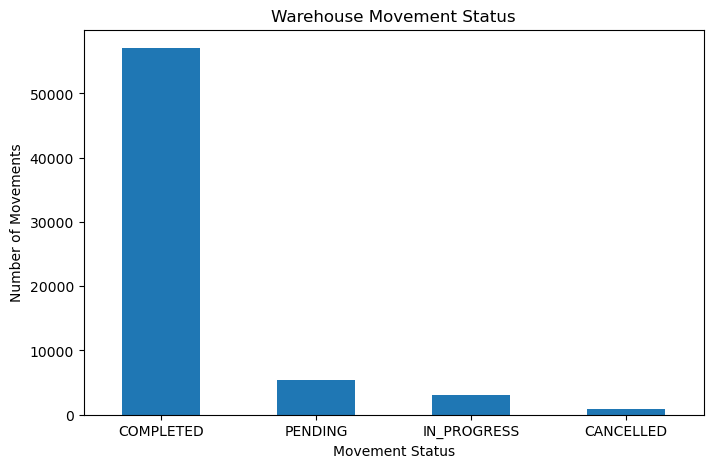

In [15]:
plt.figure(figsize=(8, 5))

status_counts.plot(kind="bar")

plt.title("Warehouse Movement Status")
plt.xlabel("Movement Status")
plt.ylabel("Number of Movements")
plt.xticks(rotation=0)

plt.show()

In [16]:
status_percentage = (
    movements["Status"]
    .value_counts(normalize=True)
    * 100
)

status_percentage.round(2)

Status
COMPLETED      85.90
PENDING         8.14
IN_PROGRESS     4.51
CANCELLED       1.45
Name: proportion, dtype: float64

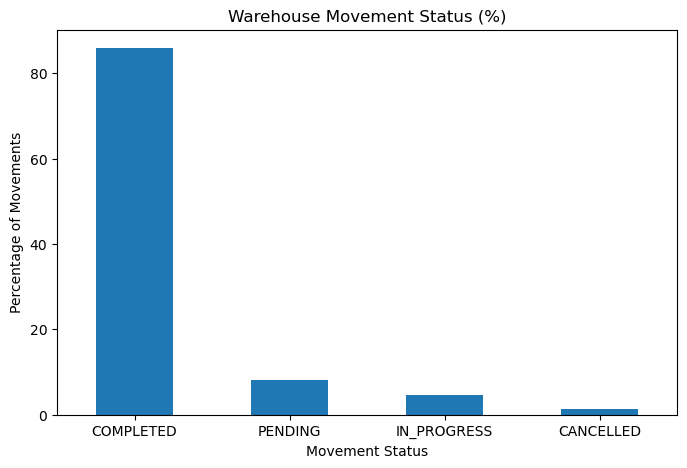

In [17]:
plt.figure(figsize=(8, 5))

status_percentage.plot(kind="bar")

plt.title("Warehouse Movement Status (%)")
plt.xlabel("Movement Status")
plt.ylabel("Percentage of Movements")
plt.xticks(rotation=0)

plt.show()

## Initial Business Observation

The movement-status analysis provides an overview of warehouse operational workload. 
The completion rate indicates how effectively movement requests are being processed, 
while non-completed movements represent workload that may require further investigation.

Further analysis will examine whether open movements are associated with particular 
areas, priorities, routes, or processing-time patterns.

In [19]:
print("Movements :", movements.shape)
print("Requests  :", requests.shape)
print("Inventory :", inventory.shape)
print("SKU       :", sku.shape)
print("Locations :", locations.shape)

Movements : (66425, 15)
Requests  : (50000, 7)
Inventory : (180000, 6)
SKU       : (10000, 8)
Locations : (28000, 6)


In [37]:
movements["Processing_Minutes"].describe()

count    57061.000000
mean       236.071899
std        159.510928
min         12.000000
25%        118.311038
50%        201.337785
75%        317.142407
max       1440.000000
Name: Processing_Minutes, dtype: float64

In [39]:
print("Total movements       :", total_movements)
print("Completed movements   :", completed_movements)
print("Open movements        :", open_movements)
print("Completion rate       :", round(completion_rate, 2), "%")
print("Total units moved     :", total_units)

Total movements       : 66425
Completed movements   : 57061
Open movements        : 9364
Completion rate       : 85.9 %
Total units moved     : 2286527


In [41]:
status_summary = (
    movements
    .groupby("Status")
    .agg(
        movement_count=("Movement_ID", "count"),
        units=("Quantity", "sum")
    )
    .sort_values("movement_count", ascending=False)
)

status_summary

,movement_count,units
Status,,
COMPLETED,57061,1966300
PENDING,5409,185277
IN_PROGRESS,2995,102089
CANCELLED,960,32861


In [43]:
status_summary["movement_pct"] = (
    status_summary["movement_count"]
    / len(movements)
    * 100
).round(2)

status_summary

,movement_count,units,movement_pct
Status,,,
COMPLETED,57061,1966300,85.90
PENDING,5409,185277,8.14
IN_PROGRESS,2995,102089,4.51
CANCELLED,960,32861,1.45


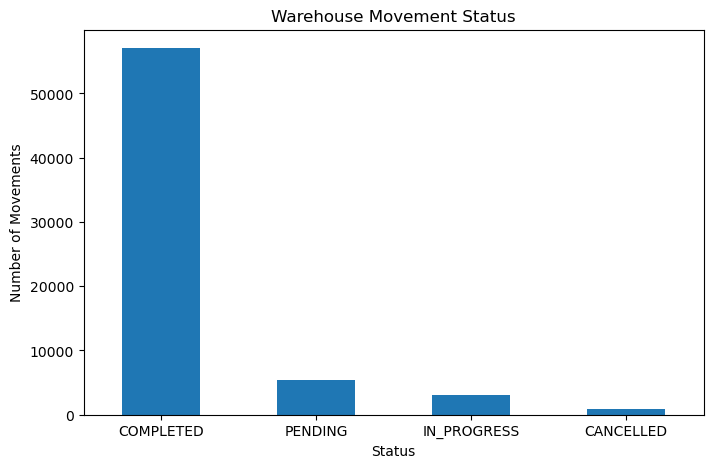

In [45]:
plt.figure(figsize=(8, 5))

status_summary["movement_count"].plot(kind="bar")

plt.title("Warehouse Movement Status")
plt.xlabel("Status")
plt.ylabel("Number of Movements")
plt.xticks(rotation=0)

plt.show()

In [47]:
backlog = movements[
    movements["Status"].isin(["PENDING", "IN_PROGRESS"])
]

print("Operational backlog:", len(backlog))

Operational backlog: 8404


In [49]:
total_movements - completed_movements

9364

In [51]:
source_area_summary = (
    movements
    .groupby("From_Area")
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum")
    )
    .sort_values("movement_count", ascending=False)
)

source_area_summary

,movement_count,total_units
From_Area,,
Screening,31817,807340
Racking,24025,1207685
Repair,9306,239007
Receiving,1277,32495


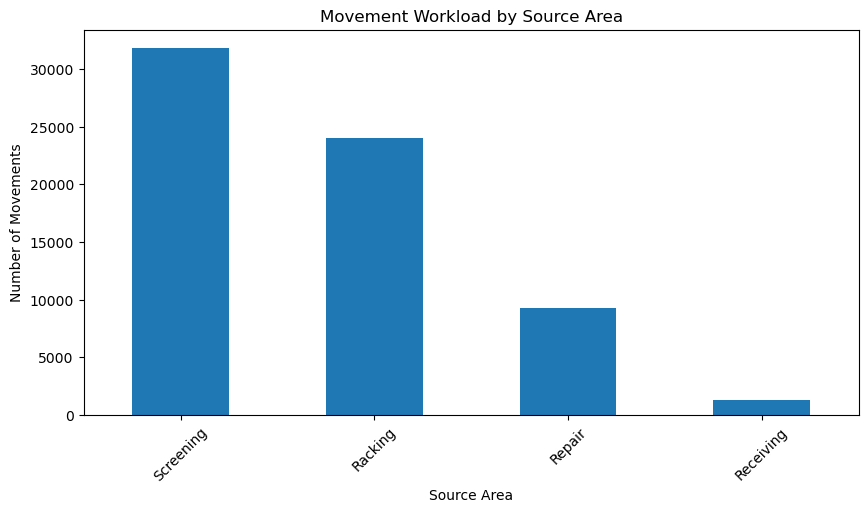

In [53]:
plt.figure(figsize=(10, 5))

source_area_summary["movement_count"].plot(kind="bar")

plt.title("Movement Workload by Source Area")
plt.xlabel("Source Area")
plt.ylabel("Number of Movements")
plt.xticks(rotation=45)

plt.show()

In [55]:
destination_area_summary = (
    movements
    .groupby("To_Area")
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum")
    )
    .sort_values("movement_count", ascending=False)
)

destination_area_summary

,movement_count,total_units
To_Area,,
Racking,38791,1219827
Repair,18414,634689
Shipping,6594,331363
Scrap,1349,68153
Screening,1277,32495


In [57]:
route_summary = (
    movements
    .groupby(["From_Area", "To_Area"])
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum"),
        avg_processing_minutes=("Processing_Minutes", "mean")
    )
    .reset_index()
    .sort_values("movement_count", ascending=False)
)

route_summary.head(15)

,From_Area,To_Area,movement_count,total_units,avg_processing_minutes
6,Screening,Racking,20061,507864,236.427409
7,Screening,Repair,11756,299476,234.324840
0,Racking,Racking,9424,472956,238.011063
5,Repair,Racking,9306,239007,237.802878
1,Racking,Repair,6658,335213,237.034846
3,Racking,Shipping,6594,331363,233.033767
2,Racking,Scrap,1349,68153,236.980721
4,Receiving,Screening,1277,32495,229.080796


In [59]:
route_matrix = pd.crosstab(
    movements["From_Area"],
    movements["To_Area"]
)

route_matrix

To_Area,Racking,Repair,Scrap,Screening,Shipping
From_Area,,,,,
Racking,9424,6658,1349,0,6594
Receiving,0,0,0,1277,0
Repair,9306,0,0,0,0
Screening,20061,11756,0,0,0


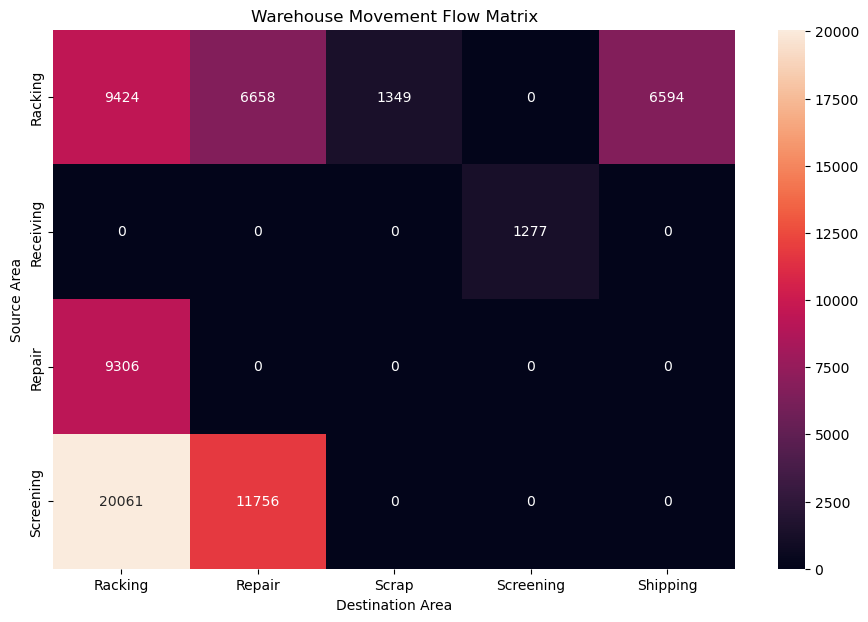

In [61]:
plt.figure(figsize=(11, 7))

sns.heatmap(
    route_matrix,
    annot=True,
    fmt="d"
)

plt.title("Warehouse Movement Flow Matrix")
plt.xlabel("Destination Area")
plt.ylabel("Source Area")

plt.show()

In [65]:
completed = movements[
    (movements["Status"] == "COMPLETED") &
    (movements["Processing_Minutes"].notna()) &
    (movements["Processing_Minutes"] >= 0)
].copy()

In [67]:
completed["Processing_Minutes"].describe()

count    57061.000000
mean       236.071899
std        159.510928
min         12.000000
25%        118.311038
50%        201.337785
75%        317.142407
max       1440.000000
Name: Processing_Minutes, dtype: float64

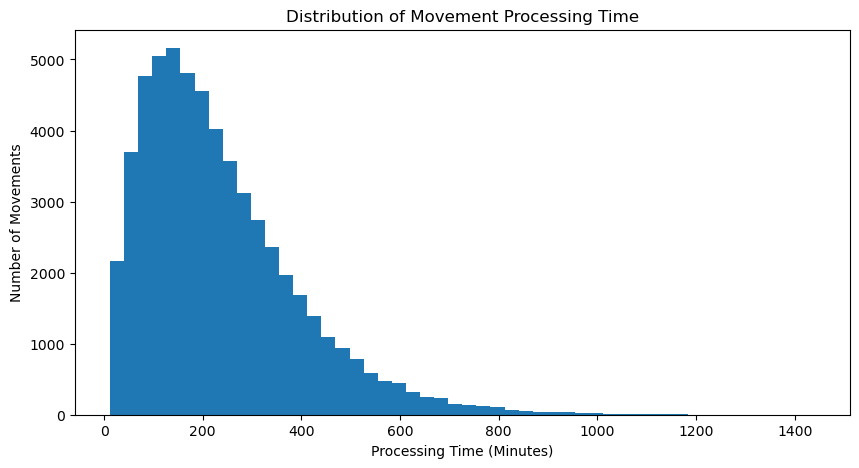

In [69]:
plt.figure(figsize=(10, 5))

plt.hist(
    completed["Processing_Minutes"],
    bins=50
)

plt.title("Distribution of Movement Processing Time")
plt.xlabel("Processing Time (Minutes)")
plt.ylabel("Number of Movements")

plt.show()

In [71]:
route_processing = (
    completed
    .groupby(["From_Area", "To_Area"])
    .agg(
        completed_movements=("Movement_ID", "count"),
        avg_processing_minutes=("Processing_Minutes", "mean"),
        median_processing_minutes=("Processing_Minutes", "median")
    )
    .reset_index()
    .sort_values("avg_processing_minutes", ascending=False)
)

route_processing.head(15)

,From_Area,To_Area,completed_movements,avg_processing_minutes,median_processing_minutes
0,Racking,Racking,8105,238.011063,201.831068
5,Repair,Racking,8029,237.802878,202.711806
1,Racking,Repair,5731,237.034846,203.484573
2,Racking,Scrap,1172,236.980721,200.850336
6,Screening,Racking,17206,236.427409,202.318834
7,Screening,Repair,10107,234.324840,200.635610
3,Racking,Shipping,5631,233.033767,197.032411
4,Receiving,Screening,1080,229.080796,193.048607


In [73]:
p95 = completed["Processing_Minutes"].quantile(0.95)

print("95th percentile processing time:", round(p95, 2), "minutes")

95th percentile processing time: 542.47 minutes


In [75]:
slow_movements = completed[
    completed["Processing_Minutes"] > p95
].copy()

print("Slow movement records:", len(slow_movements))

Slow movement records: 2853


In [77]:
slow_movements[
    [
        "Movement_ID",
        "From_Area",
        "To_Area",
        "Movement_Type",
        "Priority",
        "Quantity",
        "Processing_Minutes"
    ]
].sort_values(
    "Processing_Minutes",
    ascending=False
).head(20)

,Movement_ID,From_Area,To_Area,Movement_Type,Priority,Quantity,Processing_Minutes
41521,MOV0041522,Screening,Racking,PUTAWAY,Normal,24,1440.000000
16948,MOV0016949,Screening,Repair,DEPARTMENT_TRANSFER,Critical,22,1440.000000
60601,MOV0060602,Racking,Shipping,SHIPPING_TRANSFER,Normal,66,1440.000000
41493,MOV0041494,Racking,Shipping,SHIPPING_TRANSFER,Normal,41,1408.064925
7578,MOV0007579,Screening,Racking,PUTAWAY,Normal,12,1286.608133
9893,MOV0009894,Screening,Racking,PUTAWAY,Normal,32,1281.225238
58284,MOV0058285,Screening,Racking,PUTAWAY,Normal,34,1274.749245
63777,MOV0063778,Repair,Racking,REPAIR_TRANSFER,Normal,33,1257.025309
8064,MOV0008065,Screening,Racking,PUTAWAY,Normal,12,1243.722495
14168,MOV0014169,Racking,Racking,BIN_TO_SHELF,Critical,10,1237.024728


In [79]:
slow_movements[
    [
        "Movement_ID",
        "From_Area",
        "To_Area",
        "Movement_Type",
        "Priority",
        "Quantity",
        "Processing_Minutes"
    ]
].sort_values(
    "Processing_Minutes",
    ascending=False
).head(20)

,Movement_ID,From_Area,To_Area,Movement_Type,Priority,Quantity,Processing_Minutes
41521,MOV0041522,Screening,Racking,PUTAWAY,Normal,24,1440.000000
16948,MOV0016949,Screening,Repair,DEPARTMENT_TRANSFER,Critical,22,1440.000000
60601,MOV0060602,Racking,Shipping,SHIPPING_TRANSFER,Normal,66,1440.000000
41493,MOV0041494,Racking,Shipping,SHIPPING_TRANSFER,Normal,41,1408.064925
7578,MOV0007579,Screening,Racking,PUTAWAY,Normal,12,1286.608133
9893,MOV0009894,Screening,Racking,PUTAWAY,Normal,32,1281.225238
58284,MOV0058285,Screening,Racking,PUTAWAY,Normal,34,1274.749245
63777,MOV0063778,Repair,Racking,REPAIR_TRANSFER,Normal,33,1257.025309
8064,MOV0008065,Screening,Racking,PUTAWAY,Normal,12,1243.722495
14168,MOV0014169,Racking,Racking,BIN_TO_SHELF,Critical,10,1237.024728


In [81]:
inventory["Snapshot_Date"] = pd.to_datetime(
    inventory["Snapshot_Date"]
)

latest_snapshot_date = inventory["Snapshot_Date"].max()

print("Latest inventory snapshot:", latest_snapshot_date)

Latest inventory snapshot: 2026-09-30 00:00:00


In [83]:
current_inventory = inventory[
    inventory["Snapshot_Date"] == latest_snapshot_date
].copy()

print("Latest snapshot rows:", len(current_inventory))

Latest snapshot rows: 472


In [85]:
active_inventory = current_inventory[
    current_inventory["Quantity_On_Hand"] > 0
].copy()

In [87]:
sku_fragmentation = (
    active_inventory
    .groupby("SKU_ID")
    .agg(
        location_count=("Location_ID", "nunique"),
        total_quantity=("Quantity_On_Hand", "sum")
    )
    .reset_index()
)

In [89]:
sku_fragmentation["avg_units_per_location"] = (
    sku_fragmentation["total_quantity"]
    / sku_fragmentation["location_count"]
)

In [91]:
sku_fragmentation.sort_values(
    "location_count",
    ascending=False
).head(20)

,SKU_ID,location_count,total_quantity,avg_units_per_location
343,SKU07035,2,155,77.5
360,SKU07489,2,11,5.5
168,SKU03200,2,576,288.0
416,SKU09025,2,31,15.5
45,SKU00810,2,203,101.5
270,SKU05063,2,39,19.5
268,SKU05047,2,24,12.0
36,SKU00689,2,212,106.0
266,SKU05040,2,22,11.0
136,SKU02691,2,16,8.0


In [95]:
sku_fragmentation["fragmentation_level"] = pd.cut(
    sku_fragmentation["location_count"],
    bins=[0, 1, 3, 5, float("inf")],
    labels=[
        "Single Location",
        "Low Fragmentation",
        "Medium Fragmentation",
        "High Fragmentation"
    ]
)

In [97]:
sku_fragmentation["fragmentation_level"].value_counts()

fragmentation_level
Single Location         448
Low Fragmentation        12
Medium Fragmentation      0
High Fragmentation        0
Name: count, dtype: int64

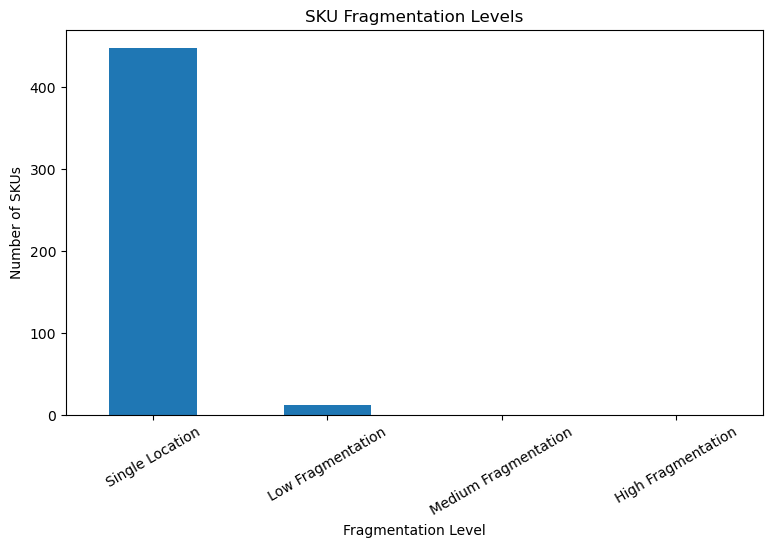

In [99]:
fragmentation_counts = (
    sku_fragmentation["fragmentation_level"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

fragmentation_counts.plot(kind="bar")

plt.title("SKU Fragmentation Levels")
plt.xlabel("Fragmentation Level")
plt.ylabel("Number of SKUs")
plt.xticks(rotation=30)

plt.show()

In [102]:
sku_fragmentation_detail = sku_fragmentation.merge(
    sku,
    on="SKU_ID",
    how="left"
)

In [104]:
sku_fragmentation_detail[
    [
        "SKU_ID",
        "Device_Type",
        "Model",
        "Category",
        "location_count",
        "total_quantity",
        "avg_units_per_location",
        "fragmentation_level"
    ]
].sort_values(
    "location_count",
    ascending=False
).head(20)

,SKU_ID,Device_Type,Model,Category,location_count,total_quantity,avg_units_per_location,fragmentation_level
343,SKU07035,iPhone,iPhone 14,Smartphone,2,155,77.5,Low Fragmentation
360,SKU07489,iPhone,iPhone 16,Smartphone,2,11,5.5,Low Fragmentation
168,SKU03200,Logic Board,MLB A,Component,2,576,288.0,Low Fragmentation
416,SKU09025,Apple Watch,Watch SE,Wearable,2,31,15.5,Low Fragmentation
45,SKU00810,Accessory,Power Adapter,Accessory,2,203,101.5,Low Fragmentation
270,SKU05063,iPhone,iPhone 14,Smartphone,2,39,19.5,Low Fragmentation
268,SKU05047,iPhone,iPhone 15,Smartphone,2,24,12.0,Low Fragmentation
36,SKU00689,Apple Watch,Watch SE,Wearable,2,212,106.0,Low Fragmentation
266,SKU05040,Apple Watch,Watch SE,Wearable,2,22,11.0,Low Fragmentation
136,SKU02691,Logic Board,MLB C,Component,2,16,8.0,Low Fragmentation


In [106]:
category_fragmentation = (
    sku_fragmentation_detail
    .groupby("Category")
    .agg(
        sku_count=("SKU_ID", "count"),
        avg_locations_per_sku=("location_count", "mean"),
        avg_quantity=("total_quantity", "mean")
    )
    .sort_values(
        "avg_locations_per_sku",
        ascending=False
    )
)

category_fragmentation

,sku_count,avg_locations_per_sku,avg_quantity
Category,,,
Component,35,1.085714,71.914286
Wearable,48,1.062500,50.833333
Accessory,22,1.045455,57.909091
Smartphone,165,1.024242,43.260606
Tablet,104,1.009615,40.980769
Computer,59,1.000000,38.762712
Media Device,27,1.000000,38.074074


In [108]:
location_inventory = (
    current_inventory
    .groupby("Location_ID")
    .agg(
        total_units=("Quantity_On_Hand", "sum"),
        capacity_units=("Capacity_Units", "max"),
        sku_count=("SKU_ID", "nunique")
    )
    .reset_index()
)

In [110]:
location_inventory["occupancy_pct"] = (
    location_inventory["total_units"]
    / location_inventory["capacity_units"]
    * 100
)

In [112]:
location_inventory["occupancy_pct"].describe()

count    469.000000
mean      42.525151
std       20.558287
min        2.941176
25%       26.568266
50%       41.935484
75%       55.555556
max      107.407407
Name: occupancy_pct, dtype: float64

In [114]:
def utilisation_band(x):
    if x > 100:
        return "OVER CAPACITY"
    elif x >= 90:
        return "HIGH"
    elif x >= 70:
        return "MEDIUM"
    else:
        return "NORMAL"


location_inventory["utilisation_status"] = (
    location_inventory["occupancy_pct"]
    .apply(utilisation_band)
)

In [116]:
location_inventory["utilisation_status"].value_counts()

utilisation_status
NORMAL           419
MEDIUM            44
HIGH               5
OVER CAPACITY      1
Name: count, dtype: int64

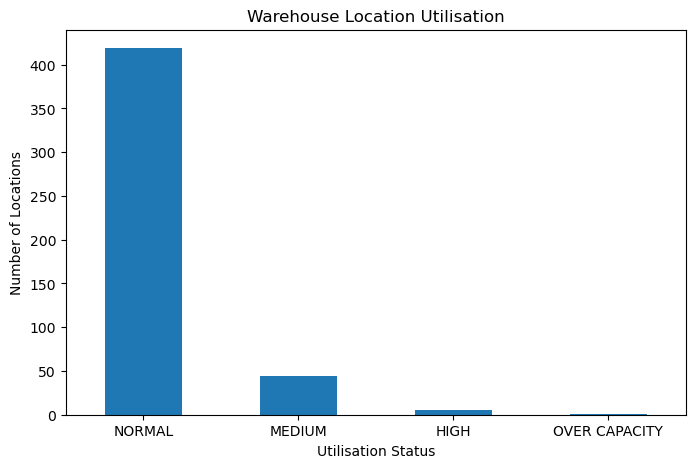

In [118]:
utilisation_counts = (
    location_inventory["utilisation_status"]
    .value_counts()
)

plt.figure(figsize=(8, 5))

utilisation_counts.plot(kind="bar")

plt.title("Warehouse Location Utilisation")
plt.xlabel("Utilisation Status")
plt.ylabel("Number of Locations")
plt.xticks(rotation=0)

plt.show()

In [120]:
location_analysis = location_inventory.merge(
    locations,
    on="Location_ID",
    how="left"
)

In [122]:
location_type_summary = (
    location_analysis
    .groupby("Location_Type")
    .agg(
        locations=("Location_ID", "count"),
        avg_occupancy_pct=("occupancy_pct", "mean"),
        median_occupancy_pct=("occupancy_pct", "median"),
        total_units=("total_units", "sum")
    )
    .sort_values(
        "avg_occupancy_pct",
        ascending=False
    )
)

location_type_summary

,locations,avg_occupancy_pct,median_occupancy_pct,total_units
Location_Type,,,,
SHELF,30,47.448580,49.167410,1412
BIN,345,42.835453,42.857143,3633
PALLET,94,39.814971,35.267743,15901


In [124]:
location_analysis[
    location_analysis["utilisation_status"].isin(
        ["HIGH", "OVER CAPACITY"]
    )
][
    [
        "Location_ID",
        "Location_Type",
        "Zone",
        "Aisle",
        "total_units",
        "capacity_units",
        "occupancy_pct",
        "sku_count",
        "utilisation_status"
    ]
].sort_values(
    "occupancy_pct",
    ascending=False
).head(25)

,Location_ID,Location_Type,Zone,Aisle,total_units,capacity_units,occupancy_pct,sku_count,utilisation_status
327,BI-19217,BIN,B,B27,29,27,107.407407,2,OVER CAPACITY
388,PA-02502,PALLET,I,I17,554,586,94.539249,1,HIGH
342,BI-19927,BIN,A,A22,31,33,93.939394,1,HIGH
94,BI-05634,BIN,D,D28,11,12,91.666667,1,HIGH
412,PA-04613,PALLET,G,G14,390,432,90.277778,1,HIGH
346,PA-00108,PALLET,I,I28,366,406,90.147783,1,HIGH


In [126]:
movements["Movement_Date"] = (
    movements["Requested_Timestamp"]
    .dt.normalize()
)

In [128]:
analysis_start_date = (
    latest_snapshot_date - pd.Timedelta(days=30)
)

recent_movements = movements[
    (movements["Movement_Date"] >= analysis_start_date) &
    (movements["Movement_Date"] <= latest_snapshot_date)
].copy()

print("Recent movement records:", len(recent_movements))

Recent movement records: 5602


In [130]:
inbound_activity = (
    recent_movements
      

    .groupby("To_Location")
    .agg(
        inbound_movements=("Movement_ID", "count"),
        inbound_units=("Quantity", "sum")
    )
    .reset_index()
    .rename(
        columns={
            "To_Location": "Location_ID"
        }
    )
)

In [132]:
location_activity = location_analysis.merge(
    inbound_activity,
    on="Location_ID",
    how="left"
)

In [134]:
location_activity[
    ["inbound_movements", "inbound_units"]
] = location_activity[
    ["inbound_movements", "inbound_units"]
].fillna(0)

In [136]:
location_activity[
    location_activity["utilisation_status"].isin(
        ["HIGH", "OVER CAPACITY"]
    )
][
    [
        "Location_ID",
        "Location_Type",
        "occupancy_pct",
        "sku_count",
        "inbound_movements",
        "inbound_units"
    ]
].sort_values(
    ["inbound_movements", "occupancy_pct"],
    ascending=False
).head(20)

,Location_ID,Location_Type,occupancy_pct,sku_count,inbound_movements,inbound_units
327,BI-19217,BIN,107.407407,2,0.0,0.0
388,PA-02502,PALLET,94.539249,1,0.0,0.0
342,BI-19927,BIN,93.939394,1,0.0,0.0
94,BI-05634,BIN,91.666667,1,0.0,0.0
412,PA-04613,PALLET,90.277778,1,0.0,0.0
346,PA-00108,PALLET,90.147783,1,0.0,0.0


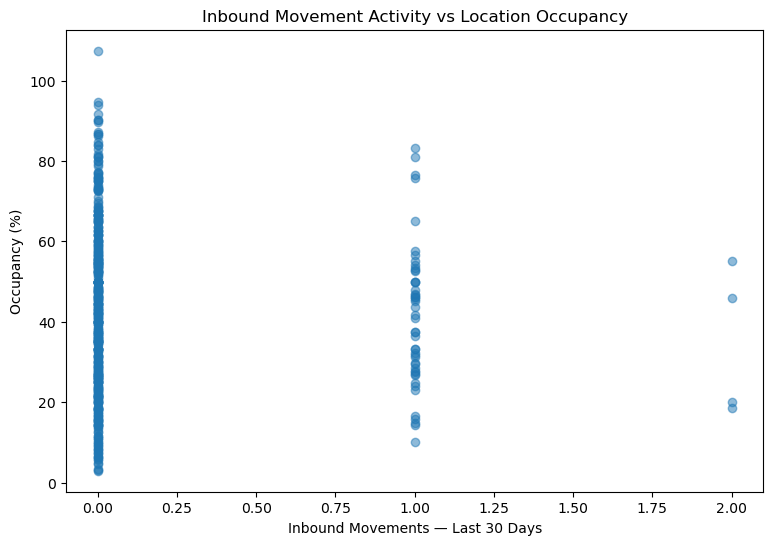

In [138]:
plt.figure(figsize=(9, 6))

plt.scatter(
    location_activity["inbound_movements"],
    location_activity["occupancy_pct"],
    alpha=0.5
)

plt.title("Inbound Movement Activity vs Location Occupancy")
plt.xlabel("Inbound Movements — Last 30 Days")
plt.ylabel("Occupancy (%)")

plt.show()

In [140]:
location_activity[
    ["inbound_movements", "occupancy_pct"]
].corr()

,inbound_movements,occupancy_pct
inbound_movements,1.000000,-0.036858
occupancy_pct,-0.036858,1.000000


In [142]:
location_activity["occupancy_score"] = (
    location_activity["occupancy_pct"]
    .clip(upper=100)
    / 100
)

In [144]:
max_movements = (
    location_activity["inbound_movements"].max()
)

location_activity["movement_score"] = (
    location_activity["inbound_movements"]
    / max_movements
)

In [146]:
location_activity["pressure_score"] = (
    0.6 * location_activity["occupancy_score"]
    +
    0.4 * location_activity["movement_score"]
)

In [148]:
location_activity[
    [
        "Location_ID",
        "Location_Type",
        "occupancy_pct",
        "inbound_movements",
        "pressure_score"
    ]
].sort_values(
    "pressure_score",
    ascending=False
).head(20)

,Location_ID,Location_Type,occupancy_pct,inbound_movements,pressure_score
466,SH-01720,SHELF,55.200000,2.0,0.731200
6,BI-00788,BIN,83.333333,1.0,0.700000
435,PA-05815,PALLET,81.070746,1.0,0.686424
121,BI-07118,BIN,45.833333,2.0,0.675000
75,BI-04653,BIN,76.470588,1.0,0.658824
402,PA-04014,PALLET,75.816993,1.0,0.654902
327,BI-19217,BIN,107.407407,0.0,0.600000
138,BI-08125,BIN,65.000000,1.0,0.590000
388,PA-02502,PALLET,94.539249,0.0,0.567235
342,BI-19927,BIN,93.939394,0.0,0.563636


In [150]:
print("========== 1. TOP 10 FRAGMENTED SKUs ==========")

top_fragmented_skus = (
    sku_fragmentation
    .sort_values("location_count", ascending=False)
    .head(10)
)

display(top_fragmented_skus)


print("\n========== 2. LOCATION TYPE SUMMARY ==========")

display(location_type_summary)


print("\n========== 3. UTILISATION STATUS COUNTS ==========")

utilisation_status_counts = (
    location_analysis["utilisation_status"]
    .value_counts()
)

display(utilisation_status_counts)


print("\n========== 4. TOP 10 HIGH-PRESSURE LOCATIONS ==========")

high_pressure_locations = (
    location_activity[
        [
            "Location_ID",
            "Location_Type",
            "occupancy_pct",
            "sku_count",
            "inbound_movements",
            "inbound_units",
            "pressure_score"
        ]
    ]
    .sort_values(
        "pressure_score",
        ascending=False
    )
    .head(10)
)

display(high_pressure_locations)


print("\n========== 5. MOVEMENT vs OCCUPANCY CORRELATION ==========")

correlation = location_activity[
    "inbound_movements"
].corr(
    location_activity["occupancy_pct"]
)

print(
    "Correlation between inbound movements and occupancy:",
    round(correlation, 4)
)

========== 1. TOP 10 FRAGMENTED SKUs ==========


,SKU_ID,location_count,total_quantity,avg_units_per_location,fragmentation_level
343,SKU07035,2,155,77.5,Low Fragmentation
360,SKU07489,2,11,5.5,Low Fragmentation
168,SKU03200,2,576,288.0,Low Fragmentation
416,SKU09025,2,31,15.5,Low Fragmentation
45,SKU00810,2,203,101.5,Low Fragmentation
270,SKU05063,2,39,19.5,Low Fragmentation
268,SKU05047,2,24,12.0,Low Fragmentation
36,SKU00689,2,212,106.0,Low Fragmentation
266,SKU05040,2,22,11.0,Low Fragmentation
136,SKU02691,2,16,8.0,Low Fragmentation



========== 2. LOCATION TYPE SUMMARY ==========


,locations,avg_occupancy_pct,median_occupancy_pct,total_units
Location_Type,,,,
SHELF,30,47.448580,49.167410,1412
BIN,345,42.835453,42.857143,3633
PALLET,94,39.814971,35.267743,15901



========== 3. UTILISATION STATUS COUNTS ==========


utilisation_status
NORMAL           419
MEDIUM            44
HIGH               5
OVER CAPACITY      1
Name: count, dtype: int64


========== 4. TOP 10 HIGH-PRESSURE LOCATIONS ==========


,Location_ID,Location_Type,occupancy_pct,sku_count,inbound_movements,inbound_units,pressure_score
466,SH-01720,SHELF,55.200000,1,2.0,66.0,0.731200
6,BI-00788,BIN,83.333333,1,1.0,10.0,0.700000
435,PA-05815,PALLET,81.070746,1,1.0,85.0,0.686424
121,BI-07118,BIN,45.833333,1,2.0,66.0,0.675000
75,BI-04653,BIN,76.470588,1,1.0,15.0,0.658824
402,PA-04014,PALLET,75.816993,1,1.0,9.0,0.654902
327,BI-19217,BIN,107.407407,2,0.0,0.0,0.600000
138,BI-08125,BIN,65.000000,1,1.0,11.0,0.590000
388,PA-02502,PALLET,94.539249,1,0.0,0.0,0.567235
342,BI-19927,BIN,93.939394,1,0.0,0.0,0.563636



========== 5. MOVEMENT vs OCCUPANCY CORRELATION ==========
Correlation between inbound movements and occupancy: -0.0369


# Stage 6 — Key Business Findings

## Key Business Findings

### 1. Warehouse Movement Performance
The dataset contains 66,425 stock movements involving approximately 2.29 million units.
Around 85.9% of recorded movements were completed.

Completed movements had a median processing time of approximately 201 minutes and
an average processing time of approximately 236 minutes, indicating a right-skewed
processing-time distribution with a smaller number of relatively slow movements.

### 2. SKU Fragmentation
SKU fragmentation was limited in the latest inventory snapshot. The most fragmented
SKUs were stored across only two locations.

Therefore, there is currently no evidence that severe SKU fragmentation represents
a major warehouse-wide operational issue in this dataset.

### 3. Location Utilisation
Most represented storage locations operated within normal capacity levels.

Of 469 active locations analysed:
- 419 were classified as NORMAL
- 44 as MEDIUM utilisation
- 5 as HIGH utilisation
- 1 as OVER CAPACITY

This suggests overall storage utilisation is healthy, although a small number of
locations require closer monitoring.

### 4. Storage Type Utilisation
SHELF storage had the highest average utilisation at approximately 47.4%, followed
by BIN locations at approximately 42.8% and PALLET locations at approximately 39.8%.

The differences are moderate, but SHELF capacity may warrant comparatively closer
monitoring.

### 5. Capacity Exception
BIN location BI-19217 recorded occupancy of approximately 107.4%, exceeding its
configured capacity.

In a real operational environment this would require investigation to determine
whether the issue represents physical overflow, incorrect capacity configuration,
inventory-recording error, or temporary operational conditions.

### 6. Movement Activity vs Occupancy
The correlation between recent inbound movement count and location occupancy was
approximately -0.037.

This indicates virtually no linear relationship between recent inbound movement
frequency and current location utilisation in the analysed sample. Therefore,
recent movement frequency alone does not explain location occupancy.

### 7. Pressure-Score Evaluation
The initial exploratory location pressure score successfully combined utilisation
and movement activity, but analysis showed that locations with only a small number
of inbound movements could receive disproportionately high scores.

The scoring methodology should therefore be refined before being used for
operational decision-making.

In [154]:
location_activity["occupancy_rank"] = (
    location_activity["occupancy_pct"]
    .rank(pct=True)
)

location_activity["movement_rank"] = (
    location_activity["inbound_movements"]
    .rank(pct=True)
)

location_activity["sku_rank"] = (
    location_activity["sku_count"]
    .rank(pct=True)
)

location_activity["pressure_score_v2"] = (
    0.50 * location_activity["occupancy_rank"]
    + 0.35 * location_activity["movement_rank"]
    + 0.15 * location_activity["sku_rank"]
)

In [156]:
top_pressure_v2 = (
    location_activity[
        [
            "Location_ID",
            "Location_Type",
            "occupancy_pct",
            "sku_count",
            "inbound_movements",
            "inbound_units",
            "pressure_score_v2"
        ]
    ]
    .sort_values(
        "pressure_score_v2",
        ascending=False
    )
    .head(20)
)

top_pressure_v2

,Location_ID,Location_Type,occupancy_pct,sku_count,inbound_movements,inbound_units,pressure_score_v2
6,BI-00788,BIN,83.333333,1,1.0,10.0,0.889232
435,PA-05815,PALLET,81.070746,1,1.0,85.0,0.884968
75,BI-04653,BIN,76.470588,1,1.0,15.0,0.873774
402,PA-04014,PALLET,75.816993,1,1.0,9.0,0.868977
138,BI-08125,BIN,65.000000,1,1.0,11.0,0.827932
327,BI-19217,BIN,107.407407,2,0.0,0.0,0.805650
466,SH-01720,SHELF,55.200000,1,2.0,66.0,0.795629
155,BI-09566,BIN,57.692308,1,1.0,38.0,0.794350
223,BI-13781,BIN,84.000000,2,0.0,0.0,0.792324
347,PA-00132,PALLET,56.712329,1,1.0,78.0,0.787953


In [158]:
route_performance = route_summary.merge(
    route_processing,
    on=["From_Area", "To_Area"],
    how="left"
)

In [162]:
route_performance.head()

,From_Area,To_Area,movement_count,total_units,avg_processing_minutes_x,completed_movements,avg_processing_minutes_y,median_processing_minutes
0,Screening,Racking,20061,507864,236.427409,17206,236.427409,202.318834
1,Screening,Repair,11756,299476,234.324840,10107,234.324840,200.635610
2,Racking,Racking,9424,472956,238.011063,8105,238.011063,201.831068
3,Repair,Racking,9306,239007,237.802878,8029,237.802878,202.711806
4,Racking,Repair,6658,335213,237.034846,5731,237.034846,203.484573


In [164]:
route_performance["volume_rank"] = (
    route_performance["movement_count"]
    .rank(pct=True)
)

route_performance["delay_rank"] = (
    route_performance["avg_processing_minutes_y"]
    .rank(pct=True)
)

In [168]:
route_performance.columns

Index(['From_Area', 'To_Area', 'movement_count', 'total_units',
       'avg_processing_minutes_x', 'completed_movements',
       'avg_processing_minutes_y', 'median_processing_minutes', 'volume_rank',
       'delay_rank'],
      dtype='object')

In [170]:
route_performance["route_risk_score"] = (
    0.55 * route_performance["volume_rank"]
    + 0.45 * route_performance["delay_rank"]
)

In [172]:
route_performance[
    [
        "From_Area",
        "To_Area",
        "movement_count",
        "total_units",
        "avg_processing_minutes_y",
        "route_risk_score"
    ]
].sort_values(
    "route_risk_score",
    ascending=False
).head(15)

,From_Area,To_Area,movement_count,total_units,avg_processing_minutes_y,route_risk_score
2,Racking,Racking,9424,472956,238.011063,0.86250
0,Screening,Racking,20061,507864,236.427409,0.77500
3,Repair,Racking,9306,239007,237.802878,0.73750
1,Screening,Repair,11756,299476,234.324840,0.65000
4,Racking,Repair,6658,335213,237.034846,0.61250
6,Racking,Scrap,1349,68153,236.980721,0.41875
5,Racking,Shipping,6594,331363,233.033767,0.31875
7,Receiving,Screening,1277,32495,229.080796,0.12500


In [174]:
movement_threshold = route_performance["movement_count"].median()

processing_threshold = (
    route_performance["avg_processing_minutes_y"].median()
)

In [176]:
route_performance["bottleneck_flag"] = (
    (route_performance["movement_count"] > movement_threshold)
    &
    (
        route_performance["avg_processing_minutes_y"]
        > processing_threshold
    )
)

In [178]:
bottleneck_routes = (
    route_performance[
        route_performance["bottleneck_flag"]
    ]
    .sort_values(
        "route_risk_score",
        ascending=False
    )
)

bottleneck_routes[
    [
        "From_Area",
        "To_Area",
        "movement_count",
        "avg_processing_minutes_y",
        "route_risk_score"
    ]
]

,From_Area,To_Area,movement_count,avg_processing_minutes_y,route_risk_score
2,Racking,Racking,9424,238.011063,0.8625
3,Repair,Racking,9306,237.802878,0.7375


In [180]:
priority_analysis = (
    completed
    .groupby("Priority")
    .agg(
        completed_movements=("Movement_ID", "count"),
        avg_processing_minutes=("Processing_Minutes", "mean"),
        median_processing_minutes=("Processing_Minutes", "median")
    )
    .sort_values(
        "avg_processing_minutes"
    )
)

priority_analysis

,completed_movements,avg_processing_minutes,median_processing_minutes
Priority,,,
Normal,44593,235.734823,201.223661
Critical,2919,237.156701,205.862366
High,9549,237.314409,200.074422


In [182]:
movement_type_analysis = (
    completed
    .groupby("Movement_Type")
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum"),
        avg_processing_minutes=("Processing_Minutes", "mean"),
        median_processing_minutes=("Processing_Minutes", "median")
    )
    .sort_values(
        "avg_processing_minutes",
        ascending=False
    )
)

movement_type_analysis

,movement_count,total_units,avg_processing_minutes,median_processing_minutes
Movement_Type,,,,
BIN_TO_SHELF,2344,118897,242.170336,206.998636
SHELF_TO_PALLET,1189,59127,240.700081,198.372163
REPAIR_TRANSFER,8029,207057,237.802878,202.711806
SCRAP_TRANSFER,1172,59076,236.980721,200.850336
PUTAWAY,17206,434595,236.427409,202.318834
DEPARTMENT_TRANSFER,15838,546270,235.305459,201.963765
BIN_TO_BIN,4572,231371,235.179353,199.880603
SHIPPING_TRANSFER,5631,282310,233.033767,197.032411
RECEIVING_TRANSFER,1080,27597,229.080796,193.048607


In [184]:
route_performance["risk_level"] = pd.cut(
    route_performance["route_risk_score"],
    bins=[0, 0.4, 0.7, 1.0],
    labels=["LOW", "MEDIUM", "HIGH"],
    include_lowest=True
)

In [186]:
manager_route_table = (
    route_performance[
        [
            "From_Area",
            "To_Area",
            "movement_count",
            "total_units",
            "avg_processing_minutes_y",
            "route_risk_score",
            "risk_level"
        ]
    ]
    .sort_values(
        "route_risk_score",
        ascending=False
    )
)

manager_route_table.head(20)

,From_Area,To_Area,movement_count,total_units,avg_processing_minutes_y,route_risk_score,risk_level
2,Racking,Racking,9424,472956,238.011063,0.86250,HIGH
0,Screening,Racking,20061,507864,236.427409,0.77500,HIGH
3,Repair,Racking,9306,239007,237.802878,0.73750,HIGH
1,Screening,Repair,11756,299476,234.324840,0.65000,MEDIUM
4,Racking,Repair,6658,335213,237.034846,0.61250,MEDIUM
6,Racking,Scrap,1349,68153,236.980721,0.41875,MEDIUM
5,Racking,Shipping,6594,331363,233.033767,0.31875,LOW
7,Receiving,Screening,1277,32495,229.080796,0.12500,LOW


In [188]:
manager_route_table = (
    route_performance[
        [
            "From_Area",
            "To_Area",
            "movement_count",
            "total_units",
            "avg_processing_minutes_y",
            "route_risk_score",
            "risk_level"
        ]
    ]
    .sort_values(
        "route_risk_score",
        ascending=False
    )
)

manager_route_table.head(20)

,From_Area,To_Area,movement_count,total_units,avg_processing_minutes_y,route_risk_score,risk_level
2,Racking,Racking,9424,472956,238.011063,0.86250,HIGH
0,Screening,Racking,20061,507864,236.427409,0.77500,HIGH
3,Repair,Racking,9306,239007,237.802878,0.73750,HIGH
1,Screening,Repair,11756,299476,234.324840,0.65000,MEDIUM
4,Racking,Repair,6658,335213,237.034846,0.61250,MEDIUM
6,Racking,Scrap,1349,68153,236.980721,0.41875,MEDIUM
5,Racking,Shipping,6594,331363,233.033767,0.31875,LOW
7,Receiving,Screening,1277,32495,229.080796,0.12500,LOW


In [190]:
location_activity["location_risk_level"] = pd.cut(
    location_activity["pressure_score_v2"],
    bins=[0, 0.4, 0.7, 1.0],
    labels=["LOW", "MEDIUM", "HIGH"],
    include_lowest=True
)

In [192]:
manager_location_table = (
    location_activity[
        [
            "Location_ID",
            "Location_Type",
            "occupancy_pct",
            "sku_count",
            "inbound_movements",
            "inbound_units",
            "pressure_score_v2",
            "location_risk_level"
        ]
    ]
    .sort_values(
        "pressure_score_v2",
        ascending=False
    )
)

manager_location_table.head(20)

,Location_ID,Location_Type,occupancy_pct,sku_count,inbound_movements,inbound_units,pressure_score_v2,location_risk_level
6,BI-00788,BIN,83.333333,1,1.0,10.0,0.889232,HIGH
435,PA-05815,PALLET,81.070746,1,1.0,85.0,0.884968,HIGH
75,BI-04653,BIN,76.470588,1,1.0,15.0,0.873774,HIGH
402,PA-04014,PALLET,75.816993,1,1.0,9.0,0.868977,HIGH
138,BI-08125,BIN,65.000000,1,1.0,11.0,0.827932,HIGH
327,BI-19217,BIN,107.407407,2,0.0,0.0,0.805650,HIGH
466,SH-01720,SHELF,55.200000,1,2.0,66.0,0.795629,HIGH
155,BI-09566,BIN,57.692308,1,1.0,38.0,0.794350,HIGH
223,BI-13781,BIN,84.000000,2,0.0,0.0,0.792324,HIGH
347,PA-00132,PALLET,56.712329,1,1.0,78.0,0.787953,HIGH


In [194]:
# ============================================================
# STAGE 7 — ADVANCED ANALYTICS
# Single-cell version
# ============================================================

import pandas as pd
import numpy as np

print("========== STAGE 7 STARTING ==========\n")


# ------------------------------------------------------------
# 1. IMPROVED LOCATION PRESSURE MODEL
# ------------------------------------------------------------

location_activity["occupancy_rank"] = (
    location_activity["occupancy_pct"]
    .rank(pct=True)
)

location_activity["movement_rank"] = (
    location_activity["inbound_movements"]
    .rank(pct=True)
)

location_activity["sku_rank"] = (
    location_activity["sku_count"]
    .rank(pct=True)
)

location_activity["pressure_score_v2"] = (
    0.50 * location_activity["occupancy_rank"]
    + 0.35 * location_activity["movement_rank"]
    + 0.15 * location_activity["sku_rank"]
)

top_pressure_v2 = (
    location_activity[
        [
            "Location_ID",
            "Location_Type",
            "occupancy_pct",
            "sku_count",
            "inbound_movements",
            "inbound_units",
            "pressure_score_v2"
        ]
    ]
    .sort_values(
        "pressure_score_v2",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 2. ROUTE PERFORMANCE ANALYSIS
# ------------------------------------------------------------

route_performance = (
    completed
    .groupby(["From_Area", "To_Area"])
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum"),
        avg_processing_minutes=("Processing_Minutes", "mean"),
        median_processing_minutes=("Processing_Minutes", "median")
    )
    .reset_index()
)

route_performance["volume_rank"] = (
    route_performance["movement_count"]
    .rank(pct=True)
)

route_performance["delay_rank"] = (
    route_performance["avg_processing_minutes"]
    .rank(pct=True)
)

route_performance["route_risk_score"] = (
    0.55 * route_performance["volume_rank"]
    + 0.45 * route_performance["delay_rank"]
)


# ------------------------------------------------------------
# 3. BOTTLENECK IDENTIFICATION
# ------------------------------------------------------------

movement_threshold = (
    route_performance["movement_count"]
    .median()
)

processing_threshold = (
    route_performance["avg_processing_minutes"]
    .median()
)

route_performance["bottleneck_flag"] = (
    (route_performance["movement_count"] > movement_threshold)
    &
    (
        route_performance["avg_processing_minutes"]
        > processing_threshold
    )
)

bottleneck_routes = (
    route_performance[
        route_performance["bottleneck_flag"]
    ]
    .sort_values(
        "route_risk_score",
        ascending=False
    )
)


# ------------------------------------------------------------
# 4. PRIORITY PERFORMANCE ANALYSIS
# ------------------------------------------------------------

priority_analysis = (
    completed
    .groupby("Priority")
    .agg(
        completed_movements=("Movement_ID", "count"),
        avg_processing_minutes=("Processing_Minutes", "mean"),
        median_processing_minutes=("Processing_Minutes", "median")
    )
    .sort_values(
        "avg_processing_minutes"
    )
)


# ------------------------------------------------------------
# 5. MOVEMENT TYPE PERFORMANCE
# ------------------------------------------------------------

movement_type_analysis = (
    completed
    .groupby("Movement_Type")
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum"),
        avg_processing_minutes=("Processing_Minutes", "mean"),
        median_processing_minutes=("Processing_Minutes", "median")
    )
    .sort_values(
        "avg_processing_minutes",
        ascending=False
    )
)


# ------------------------------------------------------------
# 6. ROUTE RISK LEVEL
# ------------------------------------------------------------

route_performance["risk_level"] = pd.cut(
    route_performance["route_risk_score"],
    bins=[0, 0.4, 0.7, 1.0],
    labels=["LOW", "MEDIUM", "HIGH"],
    include_lowest=True
)

manager_route_table = (
    route_performance[
        [
            "From_Area",
            "To_Area",
            "movement_count",
            "total_units",
            "avg_processing_minutes",
            "median_processing_minutes",
            "route_risk_score",
            "risk_level"
        ]
    ]
    .sort_values(
        "route_risk_score",
        ascending=False
    )
)


# ------------------------------------------------------------
# 7. LOCATION RISK LEVEL
# ------------------------------------------------------------

location_activity["location_risk_level"] = pd.cut(
    location_activity["pressure_score_v2"],
    bins=[0, 0.4, 0.7, 1.0],
    labels=["LOW", "MEDIUM", "HIGH"],
    include_lowest=True
)

manager_location_table = (
    location_activity[
        [
            "Location_ID",
            "Location_Type",
            "occupancy_pct",
            "sku_count",
            "inbound_movements",
            "inbound_units",
            "pressure_score_v2",
            "location_risk_level"
        ]
    ]
    .sort_values(
        "pressure_score_v2",
        ascending=False
    )
)


# ------------------------------------------------------------
# FINAL OUTPUTS
# ------------------------------------------------------------

print("\n========== 1. TOP 10 LOCATION PRESSURE ==========\n")
display(top_pressure_v2)


print("\n========== 2. TOP BOTTLENECK ROUTES ==========\n")
display(
    bottleneck_routes[
        [
            "From_Area",
            "To_Area",
            "movement_count",
            "total_units",
            "avg_processing_minutes",
            "route_risk_score"
        ]
    ].head(10)
)


print("\n========== 3. PRIORITY ANALYSIS ==========\n")
display(priority_analysis)


print("\n========== 4. MOVEMENT TYPE ANALYSIS ==========\n")
display(movement_type_analysis)


print("\n========== 5. TOP 10 MANAGER ROUTE RISK TABLE ==========\n")
display(manager_route_table.head(10))


print("\n========== 6. TOP 10 MANAGER LOCATION RISK TABLE ==========\n")
display(manager_location_table.head(10))


print("\n========== STAGE 7 COMPLETE ==========")

========== STAGE 7 STARTING ==========


========== 1. TOP 10 LOCATION PRESSURE ==========



,Location_ID,Location_Type,occupancy_pct,sku_count,inbound_movements,inbound_units,pressure_score_v2
6,BI-00788,BIN,83.333333,1,1.0,10.0,0.889232
435,PA-05815,PALLET,81.070746,1,1.0,85.0,0.884968
75,BI-04653,BIN,76.470588,1,1.0,15.0,0.873774
402,PA-04014,PALLET,75.816993,1,1.0,9.0,0.868977
138,BI-08125,BIN,65.000000,1,1.0,11.0,0.827932
327,BI-19217,BIN,107.407407,2,0.0,0.0,0.805650
466,SH-01720,SHELF,55.200000,1,2.0,66.0,0.795629
155,BI-09566,BIN,57.692308,1,1.0,38.0,0.794350
223,BI-13781,BIN,84.000000,2,0.0,0.0,0.792324
347,PA-00132,PALLET,56.712329,1,1.0,78.0,0.787953



========== 2. TOP BOTTLENECK ROUTES ==========



,From_Area,To_Area,movement_count,total_units,avg_processing_minutes,route_risk_score
0,Racking,Racking,8105,409395,238.011063,0.8625
5,Repair,Racking,8029,207057,237.802878,0.7375



========== 3. PRIORITY ANALYSIS ==========



...


========== 5. TOP 10 MANAGER ROUTE RISK TABLE ==========



,From_Area,To_Area,movement_count,total_units,avg_processing_minutes,median_processing_minutes,route_risk_score,risk_level
0,Racking,Racking,8105,409395,238.011063,201.831068,0.86250,HIGH
6,Screening,Racking,17206,434595,236.427409,202.318834,0.77500,HIGH
5,Repair,Racking,8029,207057,237.802878,202.711806,0.73750,HIGH
7,Screening,Repair,10107,256688,234.324840,200.635610,0.65000,MEDIUM
1,Racking,Repair,5731,289582,237.034846,203.484573,0.61250,MEDIUM
2,Racking,Scrap,1172,59076,236.980721,200.850336,0.41875,MEDIUM
3,Racking,Shipping,5631,282310,233.033767,197.032411,0.31875,LOW
4,Receiving,Screening,1080,27597,229.080796,193.048607,0.12500,LOW



========== 6. TOP 10 MANAGER LOCATION RISK TABLE ==========



,Location_ID,Location_Type,occupancy_pct,sku_count,inbound_movements,inbound_units,pressure_score_v2,location_risk_level
6,BI-00788,BIN,83.333333,1,1.0,10.0,0.889232,HIGH
435,PA-05815,PALLET,81.070746,1,1.0,85.0,0.884968,HIGH
75,BI-04653,BIN,76.470588,1,1.0,15.0,0.873774,HIGH
402,PA-04014,PALLET,75.816993,1,1.0,9.0,0.868977,HIGH
138,BI-08125,BIN,65.000000,1,1.0,11.0,0.827932,HIGH
327,BI-19217,BIN,107.407407,2,0.0,0.0,0.805650,HIGH
466,SH-01720,SHELF,55.200000,1,2.0,66.0,0.795629,HIGH
155,BI-09566,BIN,57.692308,1,1.0,38.0,0.794350,HIGH
223,BI-13781,BIN,84.000000,2,0.0,0.0,0.792324,HIGH
347,PA-00132,PALLET,56.712329,1,1.0,78.0,0.787953,HIGH



========== STAGE 7 COMPLETE ==========


# Stage 7 — Advanced Analytics Findings

## 1. Route Bottlenecks

Racking → Racking and Repair → Racking were identified as the strongest
potential bottleneck routes because they combined above-median movement
volume with above-median processing time.

Racking → Racking processed 8,105 movements and more than 409,000 units,
with an average processing time of approximately 238 minutes.

## 2. High-Volume Operational Flow

Screening → Racking was the largest movement route, handling 17,206
movements and approximately 434,595 units.

Although its processing time was not the highest, the large workload means
that even relatively small efficiency improvements could have a meaningful
operational impact.

## 3. Priority Performance

Average processing times were very similar across Normal, High and Critical
priority movements.

The analysis therefore found no clear evidence that higher-priority movements
were processed materially faster than Normal-priority work in the current
dataset.

This indicates that priority handling would be an important process area for
further operational investigation.

## 4. Movement-Type Performance

Average processing times across movement types were relatively similar,
ranging from approximately 229 to 242 minutes.

BIN_TO_SHELF movements showed the highest average processing time, while
RECEIVING_TRANSFER showed the lowest, but movement type alone does not appear
to explain a large proportion of processing-time variation.

## 5. Route Risk Ranking

The highest route-risk scores were:

1. Racking → Racking
2. Screening → Racking
3. Repair → Racking

These routes represent the strongest candidates for operational review because
they combine workload volume and processing-time risk.

## 6. Location Risk

Several locations were identified as high pressure based on occupancy,
recent inbound activity and SKU concentration.

However, the exploratory scoring model did not automatically place the
over-capacity BIN location BI-19217 at the top of the ranking.

For operational use, locations exceeding 100% capacity should therefore
receive a CRITICAL override irrespective of their composite pressure score.

## Overall Conclusion

Stage 7 converted descriptive warehouse analysis into decision-oriented
analytics by prioritising routes and locations requiring management attention.

The results suggest that operational improvement efforts should focus primarily
on high-volume internal flows and selected route bottlenecks rather than
warehouse-wide storage-capacity problems.

In [198]:
# ============================================================
# STAGE 8 — PREPARE POWER BI DATASET
# ============================================================

import pandas as pd
import os

# Load date dimension
dim_date = pd.read_csv(
    "../01_Raw_Data/dim_date.csv"
)

dim_date["Date"] = pd.to_datetime(dim_date["Date"])


# ------------------------------------------------------------
# MOVEMENT FACT TABLE
# ------------------------------------------------------------

powerbi_movements = movements.copy()

powerbi_movements["Movement_Date"] = (
    powerbi_movements["Requested_Timestamp"].dt.date
)

powerbi_movements["Movement_Date"] = pd.to_datetime(
    powerbi_movements["Movement_Date"]
)


# ------------------------------------------------------------
# SKU FRAGMENTATION TABLE
# ------------------------------------------------------------

powerbi_sku_fragmentation = (
    sku_fragmentation_detail.copy()
)


# ------------------------------------------------------------
# ROUTE RISK TABLE
# ------------------------------------------------------------

powerbi_route_risk = (
    manager_route_table.copy()
)


# ------------------------------------------------------------
# LOCATION RISK TABLE
# ------------------------------------------------------------

powerbi_location_risk = (
    manager_location_table.copy()
)


# ------------------------------------------------------------
# CREATE POWER BI FOLDER IF NEEDED
# ------------------------------------------------------------

output_folder = "../04_PowerBI"

os.makedirs(
    output_folder,
    exist_ok=True
)

output_file = os.path.join(
    output_folder,
    "WarehouseFlow_PowerBI_Data.xlsx"
)


# ------------------------------------------------------------
# EXPORT ALL TABLES INTO ONE EXCEL WORKBOOK
# ------------------------------------------------------------

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    powerbi_movements.to_excel(
        writer,
        sheet_name="Movements",
        index=False
    )

    requests.to_excel(
        writer,
        sheet_name="Requests",
        index=False
    )

    sku.to_excel(
        writer,
        sheet_name="SKU",
        index=False
    )

    locations.to_excel(
        writer,
        sheet_name="Locations",
        index=False
    )

    dim_date.to_excel(
        writer,
        sheet_name="Date",
        index=False
    )

    powerbi_route_risk.to_excel(
        writer,
        sheet_name="Route_Risk",
        index=False
    )

    powerbi_location_risk.to_excel(
        writer,
        sheet_name="Location_Risk",
        index=False
    )

    powerbi_sku_fragmentation.to_excel(
        writer,
        sheet_name="SKU_Fragment",
        index=False
    )


print("Power BI dataset created successfully.")
print("File:", output_file)

Power BI dataset created successfully.
File: ../04_PowerBI/WarehouseFlow_PowerBI_Data.xlsx


In [200]:
import os

file_path = "../04_PowerBI/WarehouseFlow_PowerBI_Data.xlsx"

print("Full path:")
print(os.path.abspath(file_path))

print("\nFile exists:")
print(os.path.exists(file_path))

Full path:
/Users/maheshakula/Documents/WarehouseFlow_Intelligence/04_PowerBI/WarehouseFlow_PowerBI_Data.xlsx

File exists:
True


In [202]:
# ============================================================
# FIX POWER BI WORKBOOK — CREATE REAL EXCEL TABLES
# ============================================================

import pandas as pd
import os
from openpyxl.worksheet.table import Table, TableStyleInfo
from openpyxl.utils import get_column_letter

output_folder = "../04_PowerBI"
os.makedirs(output_folder, exist_ok=True)

output_file = os.path.join(
    output_folder,
    "WarehouseFlow_PowerBI_Data_v2.xlsx"
)

# Tables to export
powerbi_tables = {
    "Movements": powerbi_movements,
    "Requests": requests,
    "SKU": sku,
    "Locations": locations,
    "Date": dim_date,
    "Route_Risk": manager_route_table,
    "Location_Risk": manager_location_table,
    "SKU_Fragment": sku_fragmentation_detail
}

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    for sheet_name, dataframe in powerbi_tables.items():

        # Write normal worksheet data
        dataframe.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

        worksheet = writer.book[sheet_name]

        # Find complete table range
        last_row = worksheet.max_row
        last_column = worksheet.max_column

        table_range = (
            f"A1:"
            f"{get_column_letter(last_column)}"
            f"{last_row}"
        )

        # Excel table names cannot contain spaces/special characters
        table_name = f"tbl_{sheet_name}"

        excel_table = Table(
            displayName=table_name,
            ref=table_range
        )

        style = TableStyleInfo(
            name="TableStyleMedium2",
            showFirstColumn=False,
            showLastColumn=False,
            showRowStripes=True,
            showColumnStripes=False
        )

        excel_table.tableStyleInfo = style

        worksheet.add_table(excel_table)


print("✅ Power BI-ready Excel workbook created")
print("File:", os.path.abspath(output_file))

print("\nExcel tables created:")
for name in powerbi_tables:
    print(" -", f"tbl_{name}")

✅ Power BI-ready Excel workbook created
File: /Users/maheshakula/Documents/WarehouseFlow_Intelligence/04_PowerBI/WarehouseFlow_PowerBI_Data_v2.xlsx

Excel tables created:
 - tbl_Movements
 - tbl_Requests
 - tbl_SKU
 - tbl_Locations
 - tbl_Date
 - tbl_Route_Risk
 - tbl_Location_Risk
 - tbl_SKU_Fragment


In [1]:
# ============================================================
# STAGE 9 — FORECASTING + ANOMALY DETECTION
# PART 1: DAILY WORKLOAD TIME SERIES
# ============================================================

daily_workload = (
    movements
    .groupby("Movement_Date")
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Movement_Date")
)

daily_workload.head()

NameError: name 'movements' is not defined

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load movement data
movements = pd.read_csv(
    "../01_Raw_Data/stock_movements.csv"
)

# Convert timestamps
movements["Requested_Timestamp"] = pd.to_datetime(
    movements["Requested_Timestamp"]
)

movements["Completed_Timestamp"] = pd.to_datetime(
    movements["Completed_Timestamp"]
)

# Create processing time
movements["Processing_Minutes"] = (
    movements["Completed_Timestamp"]
    - movements["Requested_Timestamp"]
).dt.total_seconds() / 60

# Create movement date
movements["Movement_Date"] = (
    movements["Requested_Timestamp"]
    .dt.normalize()
)

# Create completed-movement dataset
completed = movements[
    (movements["Status"] == "COMPLETED")
    & (movements["Processing_Minutes"].notna())
    & (movements["Processing_Minutes"] >= 0)
].copy()

print("Environment restored ✅")
print("Movements:", movements.shape)
print("Completed movements:", completed.shape)
print(
    "Date range:",
    movements["Movement_Date"].min(),
    "to",
    movements["Movement_Date"].max()
)

Environment restored ✅
Movements: (66425, 16)
Completed movements: (57061, 16)
Date range: 2025-10-01 00:00:00 to 2026-09-30 00:00:00


In [5]:
daily_workload = (
    movements
    .groupby("Movement_Date")
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Movement_Date")
)

daily_workload.head()

,Movement_Date,movement_count,total_units
0,2025-10-01,193,6460
1,2025-10-02,175,6377
2,2025-10-03,194,6947
3,2025-10-04,156,5417
4,2025-10-05,176,5989


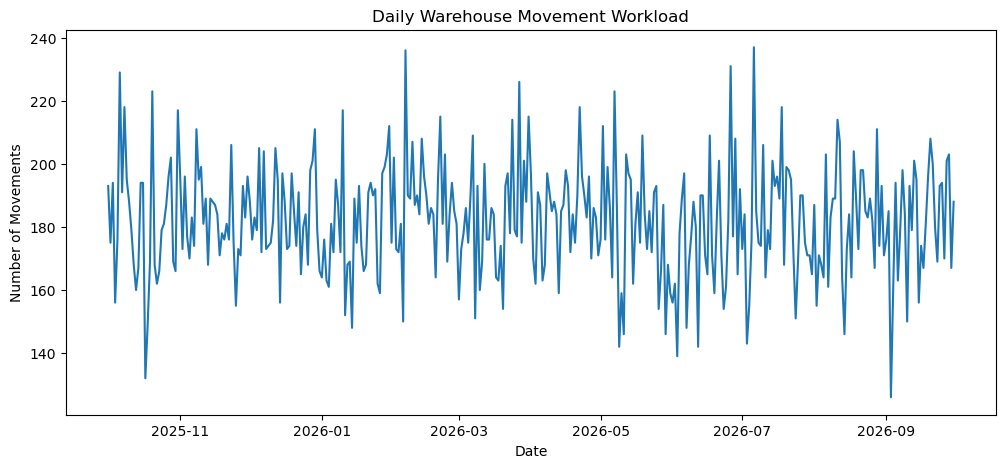

In [7]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_workload["Movement_Date"],
    daily_workload["movement_count"]
)

plt.title("Daily Warehouse Movement Workload")
plt.xlabel("Date")
plt.ylabel("Number of Movements")

plt.show()

In [9]:
daily_workload["MA_7"] = (
    daily_workload["movement_count"]
    .rolling(window=7)
    .mean()
)

daily_workload["MA_30"] = (
    daily_workload["movement_count"]
    .rolling(window=30)
    .mean()
)

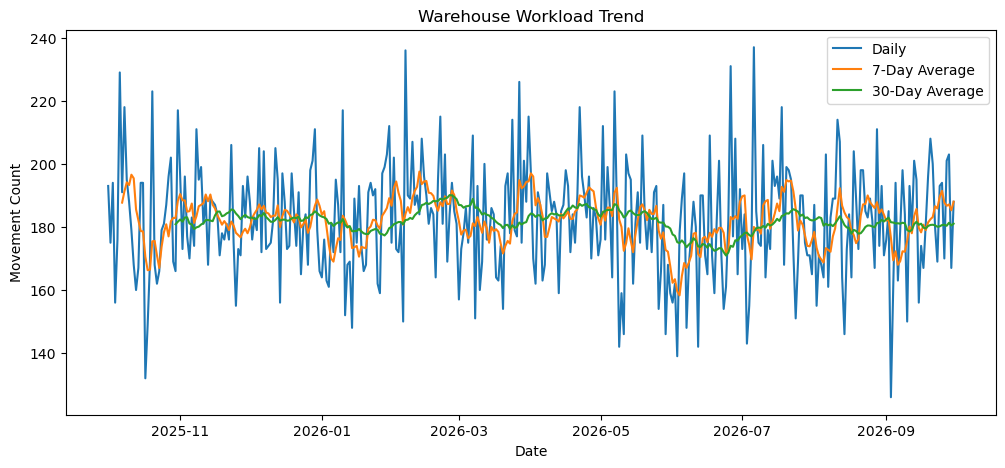

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_workload["Movement_Date"],
    daily_workload["movement_count"],
    label="Daily"
)

plt.plot(
    daily_workload["Movement_Date"],
    daily_workload["MA_7"],
    label="7-Day Average"
)

plt.plot(
    daily_workload["Movement_Date"],
    daily_workload["MA_30"],
    label="30-Day Average"
)

plt.title("Warehouse Workload Trend")
plt.xlabel("Date")
plt.ylabel("Movement Count")
plt.legend()

plt.show()

In [13]:
daily_workload["day_of_week"] = (
    daily_workload["Movement_Date"]
    .dt.dayofweek
)

daily_workload["day_of_month"] = (
    daily_workload["Movement_Date"]
    .dt.day
)

daily_workload["month"] = (
    daily_workload["Movement_Date"]
    .dt.month
)

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

In [17]:
features = [
    "day_of_week",
    "day_of_month",
    "month"
]

X = daily_workload[features]
y = daily_workload["movement_count"]

In [19]:
split_index = int(len(daily_workload) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [21]:
forecast_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

forecast_model.fit(
    X_train,
    y_train
)

RandomForestRegressor(n_estimators=200, random_state=42)

In [23]:
predictions = forecast_model.predict(X_test)

In [25]:
mae = mean_absolute_error(
    y_test,
    predictions
)

print(
    "Mean Absolute Error:",
    round(mae, 2),
    "movements"
)

Mean Absolute Error: 14.91 movements


In [27]:
forecast_results = daily_workload.iloc[
    split_index:
].copy()

forecast_results["Predicted_Movements"] = predictions

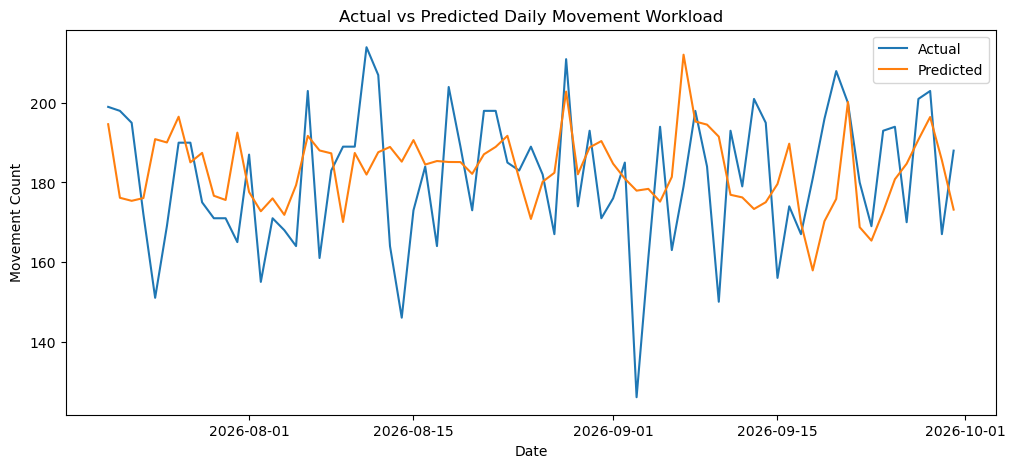

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(
    forecast_results["Movement_Date"],
    forecast_results["movement_count"],
    label="Actual"
)

plt.plot(
    forecast_results["Movement_Date"],
    forecast_results["Predicted_Movements"],
    label="Predicted"
)

plt.title("Actual vs Predicted Daily Movement Workload")
plt.xlabel("Date")
plt.ylabel("Movement Count")
plt.legend()

plt.show()

In [31]:
daily_mean = (
    daily_workload["movement_count"]
    .mean()
)

daily_std = (
    daily_workload["movement_count"]
    .std()
)

daily_workload["workload_zscore"] = (
    daily_workload["movement_count"]
    - daily_mean
) / daily_std

In [33]:
daily_workload["workload_anomaly"] = (
    daily_workload["workload_zscore"]
    .abs()
    > 2
)

In [35]:
workload_anomalies = (
    daily_workload[
        daily_workload["workload_anomaly"]
    ]
    .sort_values(
        "workload_zscore",
        ascending=False
    )
)

workload_anomalies[
    [
        "Movement_Date",
        "movement_count",
        "total_units",
        "workload_zscore"
    ]
]

,Movement_Date,movement_count,total_units,workload_zscore
278,2026-07-06,237,8938,3.118316
128,2026-02-06,236,8155,3.061634
268,2026-06-26,231,8151,2.778221
5,2025-10-06,229,7777,2.664856
177,2026-03-27,226,7658,2.494808
19,2025-10-20,223,7174,2.324761
218,2026-05-07,223,8114,2.324761
203,2026-04-22,218,8101,2.041348
290,2026-07-18,218,7599,2.041348
7,2025-10-08,218,7373,2.041348


In [37]:
processing_q1 = (
    completed["Processing_Minutes"]
    .quantile(0.25)
)

processing_q3 = (
    completed["Processing_Minutes"]
    .quantile(0.75)
)

iqr = processing_q3 - processing_q1

upper_bound = (
    processing_q3
    + 1.5 * iqr
)

print(
    "Processing-time anomaly threshold:",
    round(upper_bound, 2),
    "minutes"
)

Processing-time anomaly threshold: 615.39 minutes


In [39]:
completed["processing_anomaly"] = (
    completed["Processing_Minutes"]
    > upper_bound
)

In [41]:
processing_anomalies = (
    completed[
        completed["processing_anomaly"]
    ]
    .sort_values(
        "Processing_Minutes",
        ascending=False
    )
)

processing_anomalies[
    [
        "Movement_ID",
        "From_Area",
        "To_Area",
        "Movement_Type",
        "Priority",
        "Quantity",
        "Processing_Minutes"
    ]
].head(20)

,Movement_ID,From_Area,To_Area,Movement_Type,Priority,Quantity,Processing_Minutes
16948,MOV0016949,Screening,Repair,DEPARTMENT_TRANSFER,Critical,22,1440.000000
60601,MOV0060602,Racking,Shipping,SHIPPING_TRANSFER,Normal,66,1440.000000
41521,MOV0041522,Screening,Racking,PUTAWAY,Normal,24,1440.000000
41493,MOV0041494,Racking,Shipping,SHIPPING_TRANSFER,Normal,41,1408.064925
7578,MOV0007579,Screening,Racking,PUTAWAY,Normal,12,1286.608133
9893,MOV0009894,Screening,Racking,PUTAWAY,Normal,32,1281.225238
58284,MOV0058285,Screening,Racking,PUTAWAY,Normal,34,1274.749245
63777,MOV0063778,Repair,Racking,REPAIR_TRANSFER,Normal,33,1257.025309
8064,MOV0008065,Screening,Racking,PUTAWAY,Normal,12,1243.722495
14168,MOV0014169,Racking,Racking,BIN_TO_SHELF,Critical,10,1237.024728


In [43]:
processing_anomalies = (
    completed[
        completed["processing_anomaly"]
    ]
    .sort_values(
        "Processing_Minutes",
        ascending=False
    )
)

processing_anomalies[
    [
        "Movement_ID",
        "From_Area",
        "To_Area",
        "Movement_Type",
        "Priority",
        "Quantity",
        "Processing_Minutes"
    ]
].head(20)

,Movement_ID,From_Area,To_Area,Movement_Type,Priority,Quantity,Processing_Minutes
16948,MOV0016949,Screening,Repair,DEPARTMENT_TRANSFER,Critical,22,1440.000000
60601,MOV0060602,Racking,Shipping,SHIPPING_TRANSFER,Normal,66,1440.000000
41521,MOV0041522,Screening,Racking,PUTAWAY,Normal,24,1440.000000
41493,MOV0041494,Racking,Shipping,SHIPPING_TRANSFER,Normal,41,1408.064925
7578,MOV0007579,Screening,Racking,PUTAWAY,Normal,12,1286.608133
9893,MOV0009894,Screening,Racking,PUTAWAY,Normal,32,1281.225238
58284,MOV0058285,Screening,Racking,PUTAWAY,Normal,34,1274.749245
63777,MOV0063778,Repair,Racking,REPAIR_TRANSFER,Normal,33,1257.025309
8064,MOV0008065,Screening,Racking,PUTAWAY,Normal,12,1243.722495
14168,MOV0014169,Racking,Racking,BIN_TO_SHELF,Critical,10,1237.024728


In [45]:
operational_alerts = processing_anomalies[
    [
        "Movement_ID",
        "Movement_Date",
        "From_Area",
        "To_Area",
        "Movement_Type",
        "Priority",
        "Quantity",
        "Processing_Minutes"
    ]
].copy()

operational_alerts["Alert_Type"] = (
    "PROCESSING_TIME_ANOMALY"
)

operational_alerts.head()

,Movement_ID,Movement_Date,From_Area,To_Area,Movement_Type,Priority,Quantity,Processing_Minutes,Alert_Type
16948,MOV0016949,2025-11-15,Screening,Repair,DEPARTMENT_TRANSFER,Critical,22,1440.000000,PROCESSING_TIME_ANOMALY
60601,MOV0060602,2026-08-31,Racking,Shipping,SHIPPING_TRANSFER,Normal,66,1440.000000,PROCESSING_TIME_ANOMALY
41521,MOV0041522,2026-04-11,Screening,Racking,PUTAWAY,Normal,24,1440.000000,PROCESSING_TIME_ANOMALY
41493,MOV0041494,2026-04-26,Racking,Shipping,SHIPPING_TRANSFER,Normal,41,1408.064925,PROCESSING_TIME_ANOMALY
7578,MOV0007579,2026-02-13,Screening,Racking,PUTAWAY,Normal,12,1286.608133,PROCESSING_TIME_ANOMALY


In [51]:
print("========== 1. DAILY WORKLOAD SUMMARY ==========\n")
display(daily_workload.describe())


print("\n========== 2. FORECAST MODEL ERROR ==========\n")
print("Mean Absolute Error:", round(mae, 2), "movements per day")


print("\n========== 3. WORKLOAD ANOMALIES ==========\n")
display(
    workload_anomalies[
        [
            "Movement_Date",
            "movement_count",
            "total_units",
            "workload_zscore"
        ]
    ]
)


print("\n========== 4. PROCESSING-TIME ANOMALY THRESHOLD ==========\n")
print(
    "Processing-time anomaly threshold:",
    round(upper_bound, 2),
    "minutes"
)


print("\n========== 5. TOP 10 PROCESSING-TIME ANOMALIES ==========\n")
display(
    processing_anomalies[
        [
            "Movement_ID",
            "From_Area",
            "To_Area",
            "Movement_Type",
            "Priority",
            "Quantity",
            "Processing_Minutes"
        ]
    ].head(10)
)

========== 1. DAILY WORKLOAD SUMMARY ==========



,Movement_Date,movement_count,total_units,MA_7,MA_30,day_of_week,day_of_month,month,workload_zscore
count,365,365.000000,365.000000,359.000000,336.000000,365.000000,365.000000,365.000000,3.650000e+02
mean,2026-04-01 00:00:00,181.986301,6264.457534,181.935933,181.823909,2.997260,15.720548,6.526027,-1.703356e-17
min,2025-10-01 00:00:00,126.000000,4406.000000,158.285714,170.933333,0.000000,1.000000,1.000000,-3.173446e+00
25%,2025-12-31 00:00:00,171.000000,5771.000000,178.000000,180.150000,1.000000,8.000000,4.000000,-6.227314e-01
50%,2026-04-01 00:00:00,182.000000,6234.000000,182.428571,182.066667,3.000000,16.000000,7.000000,7.764731e-04
75%,2026-07-01 00:00:00,194.000000,6692.000000,186.714286,183.875000,5.000000,23.000000,10.000000,6.809669e-01
max,2026-09-30 00:00:00,237.000000,8938.000000,197.571429,190.100000,6.000000,31.000000,12.000000,3.118316e+00
std,NaN,17.642118,693.427672,6.942476,3.495909,2.000685,8.808321,3.452584,1.000000e+00



========== 2. FORECAST MODEL ERROR ==========

Mean Absolute Error: 14.91 movements per day

========== 3. WORKLOAD ANOMALIES ==========



,Movement_Date,movement_count,total_units,workload_zscore
278,2026-07-06,237,8938,3.118316
128,2026-02-06,236,8155,3.061634
268,2026-06-26,231,8151,2.778221
5,2025-10-06,229,7777,2.664856
177,2026-03-27,226,7658,2.494808
19,2025-10-20,223,7174,2.324761
218,2026-05-07,223,8114,2.324761
203,2026-04-22,218,8101,2.041348
290,2026-07-18,218,7599,2.041348
7,2025-10-08,218,7373,2.041348



========== 4. PROCESSING-TIME ANOMALY THRESHOLD ==========

Processing-time anomaly threshold: 615.39 minutes

========== 5. TOP 10 PROCESSING-TIME ANOMALIES ==========



,Movement_ID,From_Area,To_Area,Movement_Type,Priority,Quantity,Processing_Minutes
16948,MOV0016949,Screening,Repair,DEPARTMENT_TRANSFER,Critical,22,1440.000000
60601,MOV0060602,Racking,Shipping,SHIPPING_TRANSFER,Normal,66,1440.000000
41521,MOV0041522,Screening,Racking,PUTAWAY,Normal,24,1440.000000
41493,MOV0041494,Racking,Shipping,SHIPPING_TRANSFER,Normal,41,1408.064925
7578,MOV0007579,Screening,Racking,PUTAWAY,Normal,12,1286.608133
9893,MOV0009894,Screening,Racking,PUTAWAY,Normal,32,1281.225238
58284,MOV0058285,Screening,Racking,PUTAWAY,Normal,34,1274.749245
63777,MOV0063778,Repair,Racking,REPAIR_TRANSFER,Normal,33,1257.025309
8064,MOV0008065,Screening,Racking,PUTAWAY,Normal,12,1243.722495
14168,MOV0014169,Racking,Racking,BIN_TO_SHELF,Critical,10,1237.024728


# Stage 9 — Forecasting & Anomaly Detection Findings

## Workload Pattern

The dataset contains 365 days of warehouse movement activity. Daily movement
volume averaged approximately 182 movements, ranging from 126 to 237 movements
per day.

Seven-day and thirty-day moving averages showed considerably less variation
than individual daily workload, indicating a relatively stable underlying
workload with short-term daily fluctuations.

## Workload Prediction

A Random Forest regression baseline model was developed using calendar
features including day of week, day of month and month.

The model achieved a Mean Absolute Error of approximately 14.9 movements per
day. Relative to average daily workload, this represents an error of roughly
8%.

The model should be treated as a baseline rather than a final production
forecast because lagged workload, trend and richer time-series features have
not yet been incorporated.

## Workload Anomalies

Using a z-score threshold of ±2, unusually high and low workload days were
identified.

The highest observed workload was 237 movements, while the lowest observed
workload was 126 movements.

These observations represent statistical workload anomalies that could be
used to trigger further operational investigation or staffing review.

## Processing-Time Anomalies

An IQR-based anomaly threshold of approximately 615 minutes was calculated for
movement processing time.

Movements exceeding this threshold were classified as unusually slow.
Several extreme observations exceeded 1,200 minutes, including records at
exactly 1,440 minutes.

Because the dataset is synthetic, the 1,440-minute upper boundary may reflect
the data-generation process and should not automatically be interpreted as a
real operational delay.

## Combined Operational Insight

Several routes previously identified as higher-risk in the advanced analytics
stage also appeared among the extreme processing-time anomalies.

This provides additional evidence that selected warehouse flows deserve
closer investigation, while avoiding claims of causation from synthetic data.

# Stage 10 — AI Supply Chain Copilot

In [57]:
# ============================================================
# STAGE 10 — AI SUPPLY CHAIN COPILOT
# PART 1: BUILD BUSINESS KNOWLEDGE LAYER
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

movements = pd.read_csv(
    "../01_Raw_Data/stock_movements.csv"
)

inventory = pd.read_csv(
    "../01_Raw_Data/inventory_snapshot.csv"
)

locations = pd.read_csv(
    "../01_Raw_Data/dim_location.csv"
)


# ------------------------------------------------------------
# PREPARE MOVEMENT DATA
# ------------------------------------------------------------

movements["Requested_Timestamp"] = pd.to_datetime(
    movements["Requested_Timestamp"]
)

movements["Completed_Timestamp"] = pd.to_datetime(
    movements["Completed_Timestamp"]
)

movements["Movement_Date"] = (
    movements["Requested_Timestamp"].dt.normalize()
)

movements["Processing_Minutes"] = (
    movements["Completed_Timestamp"]
    - movements["Requested_Timestamp"]
).dt.total_seconds() / 60


completed = movements[
    (movements["Status"] == "COMPLETED")
    & (movements["Processing_Minutes"].notna())
    & (movements["Processing_Minutes"] >= 0)
].copy()


# ------------------------------------------------------------
# CORE KPIs
# ------------------------------------------------------------

total_movements = len(movements)

completed_movements = (
    movements["Status"].eq("COMPLETED").sum()
)

pending_movements = (
    movements["Status"].eq("PENDING").sum()
)

in_progress_movements = (
    movements["Status"].eq("IN_PROGRESS").sum()
)

cancelled_movements = (
    movements["Status"].eq("CANCELLED").sum()
)

operational_backlog = (
    pending_movements + in_progress_movements
)

completion_rate = (
    completed_movements / total_movements * 100
)

total_units = movements["Quantity"].sum()

avg_processing = (
    completed["Processing_Minutes"].mean()
)

median_processing = (
    completed["Processing_Minutes"].median()
)


# ------------------------------------------------------------
# ROUTE ANALYSIS
# ------------------------------------------------------------

route_analysis = (
    completed
    .groupby(["From_Area", "To_Area"])
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum"),
        avg_processing_minutes=("Processing_Minutes", "mean")
    )
    .reset_index()
)

route_analysis["volume_rank"] = (
    route_analysis["movement_count"]
    .rank(pct=True)
)

route_analysis["delay_rank"] = (
    route_analysis["avg_processing_minutes"]
    .rank(pct=True)
)

route_analysis["route_risk_score"] = (
    0.55 * route_analysis["volume_rank"]
    + 0.45 * route_analysis["delay_rank"]
)

top_routes = (
    route_analysis
    .sort_values(
        "route_risk_score",
        ascending=False
    )
)


# ------------------------------------------------------------
# PROCESSING ANOMALIES
# ------------------------------------------------------------

q1 = completed["Processing_Minutes"].quantile(0.25)
q3 = completed["Processing_Minutes"].quantile(0.75)

iqr = q3 - q1

processing_threshold = (
    q3 + 1.5 * iqr
)

processing_anomalies = (
    completed[
        completed["Processing_Minutes"]
        > processing_threshold
    ]
    .sort_values(
        "Processing_Minutes",
        ascending=False
    )
)


# ------------------------------------------------------------
# LATEST INVENTORY SNAPSHOT
# ------------------------------------------------------------

inventory["Snapshot_Date"] = pd.to_datetime(
    inventory["Snapshot_Date"]
)

latest_snapshot_date = (
    inventory["Snapshot_Date"].max()
)

current_inventory = inventory[
    inventory["Snapshot_Date"]
    == latest_snapshot_date
].copy()

current_inventory = current_inventory[
    current_inventory["Quantity_On_Hand"] > 0
]


location_inventory = (
    current_inventory
    .groupby("Location_ID")
    .agg(
        total_units=("Quantity_On_Hand", "sum"),
        capacity_units=("Capacity_Units", "max"),
        sku_count=("SKU_ID", "nunique")
    )
    .reset_index()
)

location_inventory["occupancy_pct"] = (
    location_inventory["total_units"]
    / location_inventory["capacity_units"]
    * 100
)

location_inventory = location_inventory.merge(
    locations,
    on="Location_ID",
    how="left"
)

high_risk_locations = (
    location_inventory[
        location_inventory["occupancy_pct"] >= 90
    ]
    .sort_values(
        "occupancy_pct",
        ascending=False
    )
)


print("✅ Copilot knowledge layer created")
print()
print("Total movements:", total_movements)
print("Operational backlog:", operational_backlog)
print("Completion rate:", round(completion_rate, 2), "%")
print("Top risk routes:", len(top_routes))
print("High-utilisation locations:", len(high_risk_locations))
print("Processing anomalies:", len(processing_anomalies))

✅ Copilot knowledge layer created

Total movements: 66425
Operational backlog: 8404
Completion rate: 85.9 %
Top risk routes: 8
High-utilisation locations: 6
Processing anomalies: 1647


In [59]:
# ============================================================
# STAGE 10 — COPILOT QUESTION ENGINE
# ============================================================

def warehouse_copilot(question):

    q = question.lower().strip()

    # --------------------------------------------------------
    # MANAGER SUMMARY
    # --------------------------------------------------------

    if (
        "summary" in q
        or "overview" in q
        or "performance" in q
    ):

        return f"""
WAREHOUSE MANAGER SUMMARY

Total movements:
{total_movements:,}

Total units moved:
{total_units:,}

Completed movements:
{completed_movements:,}

Operational backlog:
{operational_backlog:,}

Completion rate:
{completion_rate:.2f}%

Average processing time:
{avg_processing:.1f} minutes

Median processing time:
{median_processing:.1f} minutes

Processing anomalies:
{len(processing_anomalies):,}

High-utilisation locations:
{len(high_risk_locations):,}

Highest-risk route:
{top_routes.iloc[0]['From_Area']} → {top_routes.iloc[0]['To_Area']}
"""


    # --------------------------------------------------------
    # BACKLOG
    # --------------------------------------------------------

    elif (
        "backlog" in q
        or "pending" in q
        or "open movement" in q
    ):

        return f"""
OPERATIONAL BACKLOG

Pending movements:
{pending_movements:,}

In-progress movements:
{in_progress_movements:,}

Total operational backlog:
{operational_backlog:,}

Cancelled movements:
{cancelled_movements:,}
"""


    # --------------------------------------------------------
    # ROUTE RISK
    # --------------------------------------------------------

    elif (
        "route" in q
        or "bottleneck" in q
    ):

        result = top_routes[
            [
                "From_Area",
                "To_Area",
                "movement_count",
                "avg_processing_minutes",
                "route_risk_score"
            ]
        ].head(5)

        return result


    # --------------------------------------------------------
    # LOCATIONS
    # --------------------------------------------------------

    elif (
        "location" in q
        or "capacity" in q
        or "occupancy" in q
    ):

        if len(high_risk_locations) == 0:

            return "No locations currently exceed 90% occupancy."

        return high_risk_locations[
            [
                "Location_ID",
                "Location_Type",
                "occupancy_pct",
                "total_units",
                "capacity_units",
                "sku_count"
            ]
        ].head(10)


    # --------------------------------------------------------
    # PROCESSING DELAYS
    # --------------------------------------------------------

    elif (
        "delay" in q
        or "slow" in q
        or "anomaly" in q
    ):

        return processing_anomalies[
            [
                "Movement_ID",
                "From_Area",
                "To_Area",
                "Movement_Type",
                "Priority",
                "Processing_Minutes"
            ]
        ].head(10)


    # --------------------------------------------------------
    # COMPLETION
    # --------------------------------------------------------

    elif (
        "completion" in q
        or "completed" in q
    ):

        return f"""
Completed movements:
{completed_movements:,}

Total movements:
{total_movements:,}

Completion rate:
{completion_rate:.2f}%
"""


    else:

        return """
I currently understand questions about:

• warehouse summary
• backlog
• route bottlenecks
• location capacity
• processing delays
• completion performance

Example:
warehouse_copilot("Which routes need attention?")
"""

In [61]:
warehouse_copilot(
    "Give me a warehouse manager summary"
)

'\nWAREHOUSE MANAGER SUMMARY\n\nTotal movements:\n66,425\n\nTotal units moved:\n2,286,527\n\nCompleted movements:\n57,061\n\nOperational backlog:\n8,404\n\nCompletion rate:\n85.90%\n\nAverage processing time:\n236.1 minutes\n\nMedian processing time:\n201.3 minutes\n\nProcessing anomalies:\n1,647\n\nHigh-utilisation locations:\n6\n\nHighest-risk route:\nRacking → Racking\n'

In [63]:
warehouse_copilot(
    "Which routes need attention?"
)

,From_Area,To_Area,movement_count,avg_processing_minutes,route_risk_score
0,Racking,Racking,8105,238.011063,0.8625
6,Screening,Racking,17206,236.427409,0.7750
5,Repair,Racking,8029,237.802878,0.7375
7,Screening,Repair,10107,234.324840,0.6500
1,Racking,Repair,5731,237.034846,0.6125


In [65]:
warehouse_copilot(
    "Show me locations with capacity problems"
)

,Location_ID,Location_Type,occupancy_pct,total_units,capacity_units,sku_count
327,BI-19217,BIN,107.407407,29,27,2
388,PA-02502,PALLET,94.539249,554,586,1
342,BI-19927,BIN,93.939394,31,33,1
94,BI-05634,BIN,91.666667,11,12,1
412,PA-04613,PALLET,90.277778,390,432,1
346,PA-00108,PALLET,90.147783,366,406,1


In [67]:
warehouse_copilot(
    "Show unusual processing delays"
)

,Movement_ID,From_Area,To_Area,Movement_Type,Priority,Processing_Minutes
16948,MOV0016949,Screening,Repair,DEPARTMENT_TRANSFER,Critical,1440.000000
60601,MOV0060602,Racking,Shipping,SHIPPING_TRANSFER,Normal,1440.000000
41521,MOV0041522,Screening,Racking,PUTAWAY,Normal,1440.000000
41493,MOV0041494,Racking,Shipping,SHIPPING_TRANSFER,Normal,1408.064925
7578,MOV0007579,Screening,Racking,PUTAWAY,Normal,1286.608133
9893,MOV0009894,Screening,Racking,PUTAWAY,Normal,1281.225238
58284,MOV0058285,Screening,Racking,PUTAWAY,Normal,1274.749245
63777,MOV0063778,Repair,Racking,REPAIR_TRANSFER,Normal,1257.025309
8064,MOV0008065,Screening,Racking,PUTAWAY,Normal,1243.722495
14168,MOV0014169,Racking,Racking,BIN_TO_SHELF,Critical,1237.024728


In [69]:
warehouse_copilot(
    "What is our backlog?"
)

'\nOPERATIONAL BACKLOG\n\nPending movements:\n5,409\n\nIn-progress movements:\n2,995\n\nTotal operational backlog:\n8,404\n\nCancelled movements:\n960\n'

In [71]:
warehouse_copilot("Give me a warehouse summary")

'\nWAREHOUSE MANAGER SUMMARY\n\nTotal movements:\n66,425\n\nTotal units moved:\n2,286,527\n\nCompleted movements:\n57,061\n\nOperational backlog:\n8,404\n\nCompletion rate:\n85.90%\n\nAverage processing time:\n236.1 minutes\n\nMedian processing time:\n201.3 minutes\n\nProcessing anomalies:\n1,647\n\nHigh-utilisation locations:\n6\n\nHighest-risk route:\nRacking → Racking\n'

In [75]:
warehouse_copilot("Which routes need attention?")

,From_Area,To_Area,movement_count,avg_processing_minutes,route_risk_score
0,Racking,Racking,8105,238.011063,0.8625
6,Screening,Racking,17206,236.427409,0.7750
5,Repair,Racking,8029,237.802878,0.7375
7,Screening,Repair,10107,234.324840,0.6500
1,Racking,Repair,5731,237.034846,0.6125


In [77]:
warehouse_copilot("Which locations need attention?")

,Location_ID,Location_Type,occupancy_pct,total_units,capacity_units,sku_count
327,BI-19217,BIN,107.407407,29,27,2
388,PA-02502,PALLET,94.539249,554,586,1
342,BI-19927,BIN,93.939394,31,33,1
94,BI-05634,BIN,91.666667,11,12,1
412,PA-04613,PALLET,90.277778,390,432,1
346,PA-00108,PALLET,90.147783,366,406,1


In [79]:
warehouse_copilot("Show the worst processing delays")

,Movement_ID,From_Area,To_Area,Movement_Type,Priority,Processing_Minutes
16948,MOV0016949,Screening,Repair,DEPARTMENT_TRANSFER,Critical,1440.000000
60601,MOV0060602,Racking,Shipping,SHIPPING_TRANSFER,Normal,1440.000000
41521,MOV0041522,Screening,Racking,PUTAWAY,Normal,1440.000000
41493,MOV0041494,Racking,Shipping,SHIPPING_TRANSFER,Normal,1408.064925
7578,MOV0007579,Screening,Racking,PUTAWAY,Normal,1286.608133
9893,MOV0009894,Screening,Racking,PUTAWAY,Normal,1281.225238
58284,MOV0058285,Screening,Racking,PUTAWAY,Normal,1274.749245
63777,MOV0063778,Repair,Racking,REPAIR_TRANSFER,Normal,1257.025309
8064,MOV0008065,Screening,Racking,PUTAWAY,Normal,1243.722495
14168,MOV0014169,Racking,Racking,BIN_TO_SHELF,Critical,1237.024728


In [81]:
!pip install -q openai

In [3]:
import os
from getpass import getpass

os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key: ")

Enter your OpenAI API key:  ········


In [5]:
from openai import OpenAI

client = OpenAI()

response = client.responses.create(
    model="gpt-6-luna",
    input="Reply only with: Warehouse Copilot API connected"
)

print(response.output_text)

ImportError: cannot import name 'OpenAI' from 'openai' (/opt/anaconda3/lib/python3.12/site-packages/openai/__init__.py)

In [7]:
from openai import OpenAI

ImportError: cannot import name 'OpenAI' from 'openai' (/opt/anaconda3/lib/python3.12/site-packages/openai/__init__.py)

In [9]:
import sys
import subprocess

print("Python:", sys.executable)

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--upgrade",
    "openai"
])

print("OpenAI package upgraded.")

Python: /opt/anaconda3/bin/python
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 3.9 MB/s eta 0:00:00a 0:00:01
Using cached h11-0.16.0-py3-none-any.whl (37 kB)
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.13.2
    Uninstalling typing_extensions-4.13.2:
      Successfully uninstalled typing_extensions-4.13.2
  Attempting uninstall: truststore
    Found existing installation: truststore 0.8.0
    Uninstalling truststore-0.8.0:
      Successfully uninstalled truststore-0.8.0
  Attempting uninstall: jiter
    Found existing installation: jiter 0.9.0
    Uninstalling jiter-0.9.0:
      Successfully uninstalled jiter-0.9.0
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10
  Attempting uninstall: h11
    Found existing installation: h11 0.14.0
    Uninstalling h11-0.14.0:
      Successf

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
httpcore 1.0.8 requires h11<0.15,>=0.13, but you have h11 0.16.0 which is incompatible.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 25.0 which is incompatible.
spyder 5.5.1 requires ipython!=8.17.1,<9.0.0,>=8.13.0; python_version > "3.8", but you have ipython 9.1.0 which is incompatible.


In [1]:
import os
from getpass import getpass

os.environ["OPENAI_API_KEY"] = getpass(
    "Enter your OpenAI API key: "
)

Enter your OpenAI API key:  ········


In [2]:
from openai import OpenAI

client = OpenAI()

response = client.responses.create(
    model="gpt-6-luna",
    input="Reply only with: Warehouse Copilot API connected"
)

print(response.output_text)

Warehouse Copilot API connected


In [5]:
from openai import OpenAI
import pandas as pd

client = OpenAI()


def ai_warehouse_copilot(question):

    # ---------------------------------------------------------
    # 1. GET TRUSTED ANALYTICS RESULT
    # ---------------------------------------------------------

    analytics_result = warehouse_copilot(question)

    # Convert DataFrame output into text for the LLM
    if isinstance(analytics_result, pd.DataFrame):
        analytics_context = analytics_result.to_string(index=False)
    else:
        analytics_context = str(analytics_result)


    # ---------------------------------------------------------
    # 2. SEND ANALYTICS CONTEXT TO OPENAI
    # ---------------------------------------------------------

    prompt = f"""
You are WarehouseFlow Intelligence, an AI supply-chain analytics copilot.

The warehouse dataset is synthetic and is used for a portfolio project.

Your job is to explain warehouse analytics to an operations manager.

IMPORTANT RULES:
- Use only the analytics information provided below.
- Never invent KPI values.
- Never invent causes that are not supported by the data.
- Clearly distinguish observations from possible explanations.
- Keep recommendations practical.
- If evidence is insufficient, say so.
- Do not claim synthetic anomalies are real operational incidents.

USER QUESTION:
{question}

TRUSTED ANALYTICS RESULT:
{analytics_context}

Respond using this structure when appropriate:

1. Key finding
2. Why it matters
3. Recommended action
4. Caveat / limitation

Keep the answer concise and manager-friendly.
"""


    response = client.responses.create(
        model="gpt-5.6-terra",
        reasoning={
            "effort": "low"
        },
        input=prompt
    )

    return response.output_text

In [4]:
print(
    ai_warehouse_copilot(
        "Give me a warehouse manager summary"
    )
)

NameError: name 'warehouse_copilot' is not defined

In [6]:
import pandas as pd
import numpy as np

# ============================================================
# REBUILD STAGE 10 ANALYTICS BRAIN
# ============================================================

# Load data
movements = pd.read_csv("../01_Raw_Data/stock_movements.csv")
inventory = pd.read_csv("../01_Raw_Data/inventory_snapshot.csv")
locations = pd.read_csv("../01_Raw_Data/dim_location.csv")

# Prepare movement data
movements["Requested_Timestamp"] = pd.to_datetime(
    movements["Requested_Timestamp"]
)

movements["Completed_Timestamp"] = pd.to_datetime(
    movements["Completed_Timestamp"]
)

movements["Movement_Date"] = (
    movements["Requested_Timestamp"].dt.normalize()
)

movements["Processing_Minutes"] = (
    movements["Completed_Timestamp"]
    - movements["Requested_Timestamp"]
).dt.total_seconds() / 60

completed = movements[
    (movements["Status"] == "COMPLETED")
    & (movements["Processing_Minutes"].notna())
    & (movements["Processing_Minutes"] >= 0)
].copy()

# ============================================================
# CORE KPIs
# ============================================================

total_movements = len(movements)
total_units = movements["Quantity"].sum()

completed_movements = movements["Status"].eq("COMPLETED").sum()
pending_movements = movements["Status"].eq("PENDING").sum()
in_progress_movements = movements["Status"].eq("IN_PROGRESS").sum()
cancelled_movements = movements["Status"].eq("CANCELLED").sum()

operational_backlog = (
    pending_movements + in_progress_movements
)

completion_rate = (
    completed_movements / total_movements * 100
)

avg_processing = completed["Processing_Minutes"].mean()
median_processing = completed["Processing_Minutes"].median()

# ============================================================
# ROUTE ANALYSIS
# ============================================================

route_analysis = (
    completed
    .groupby(["From_Area", "To_Area"])
    .agg(
        movement_count=("Movement_ID", "count"),
        total_units=("Quantity", "sum"),
        avg_processing_minutes=("Processing_Minutes", "mean")
    )
    .reset_index()
)

route_analysis["volume_rank"] = (
    route_analysis["movement_count"].rank(pct=True)
)

route_analysis["delay_rank"] = (
    route_analysis["avg_processing_minutes"].rank(pct=True)
)

route_analysis["route_risk_score"] = (
    0.55 * route_analysis["volume_rank"]
    + 0.45 * route_analysis["delay_rank"]
)

top_routes = (
    route_analysis
    .sort_values("route_risk_score", ascending=False)
)

# ============================================================
# PROCESSING ANOMALIES
# ============================================================

q1 = completed["Processing_Minutes"].quantile(0.25)
q3 = completed["Processing_Minutes"].quantile(0.75)
iqr = q3 - q1

processing_threshold = q3 + 1.5 * iqr

processing_anomalies = (
    completed[
        completed["Processing_Minutes"] > processing_threshold
    ]
    .sort_values("Processing_Minutes", ascending=False)
)

# ============================================================
# LOCATION ANALYSIS
# ============================================================

inventory["Snapshot_Date"] = pd.to_datetime(
    inventory["Snapshot_Date"]
)

latest_snapshot_date = inventory["Snapshot_Date"].max()

current_inventory = inventory[
    (inventory["Snapshot_Date"] == latest_snapshot_date)
    & (inventory["Quantity_On_Hand"] > 0)
].copy()

location_inventory = (
    current_inventory
    .groupby("Location_ID")
    .agg(
        total_units=("Quantity_On_Hand", "sum"),
        capacity_units=("Capacity_Units", "max"),
        sku_count=("SKU_ID", "nunique")
    )
    .reset_index()
)

location_inventory["occupancy_pct"] = (
    location_inventory["total_units"]
    / location_inventory["capacity_units"]
    * 100
)

location_inventory = location_inventory.merge(
    locations,
    on="Location_ID",
    how="left"
)

high_risk_locations = (
    location_inventory[
        location_inventory["occupancy_pct"] >= 90
    ]
    .sort_values("occupancy_pct", ascending=False)
)

# ============================================================
# RULE-BASED WAREHOUSE COPILOT
# ============================================================

def warehouse_copilot(question):

    q = question.lower().strip()

    if (
        "summary" in q
        or "overview" in q
        or "performance" in q
    ):
        return f"""
WAREHOUSE MANAGER SUMMARY

Total movements: {total_movements:,}
Total units moved: {total_units:,}
Completed movements: {completed_movements:,}
Operational backlog: {operational_backlog:,}
Completion rate: {completion_rate:.2f}%
Average processing time: {avg_processing:.1f} minutes
Median processing time: {median_processing:.1f} minutes
Processing anomalies: {len(processing_anomalies):,}
High-utilisation locations: {len(high_risk_locations):,}

Highest-risk route:
{top_routes.iloc[0]['From_Area']} → {top_routes.iloc[0]['To_Area']}
"""

    elif (
        "backlog" in q
        or "pending" in q
        or "open movement" in q
    ):
        return f"""
Pending movements: {pending_movements:,}
In-progress movements: {in_progress_movements:,}
Operational backlog: {operational_backlog:,}
Cancelled movements: {cancelled_movements:,}
"""

    elif (
        "route" in q
        or "bottleneck" in q
    ):
        return top_routes[
            [
                "From_Area",
                "To_Area",
                "movement_count",
                "avg_processing_minutes",
                "route_risk_score"
            ]
        ].head(5)

    elif (
        "location" in q
        or "capacity" in q
        or "occupancy" in q
    ):
        return high_risk_locations[
            [
                "Location_ID",
                "Location_Type",
                "occupancy_pct",
                "total_units",
                "capacity_units",
                "sku_count"
            ]
        ].head(10)

    elif (
        "delay" in q
        or "slow" in q
        or "anomaly" in q
    ):
        return processing_anomalies[
            [
                "Movement_ID",
                "From_Area",
                "To_Area",
                "Movement_Type",
                "Priority",
                "Processing_Minutes"
            ]
        ].head(10)

    elif (
        "completion" in q
        or "completed" in q
    ):
        return f"""
Completed movements: {completed_movements:,}
Total movements: {total_movements:,}
Completion rate: {completion_rate:.2f}%
"""

    else:
        return """
I currently understand questions about:
- warehouse summary
- backlog
- route bottlenecks
- location capacity
- processing delays
- completion performance
"""


print("✅ warehouse_copilot rebuilt successfully")

✅ warehouse_copilot rebuilt successfully


In [7]:
warehouse_copilot("Give me a warehouse manager summary")

'\nWAREHOUSE MANAGER SUMMARY\n\nTotal movements: 66,425\nTotal units moved: 2,286,527\nCompleted movements: 57,061\nOperational backlog: 8,404\nCompletion rate: 85.90%\nAverage processing time: 236.1 minutes\nMedian processing time: 201.3 minutes\nProcessing anomalies: 1,647\nHigh-utilisation locations: 6\n\nHighest-risk route:\nRacking → Racking\n'

In [8]:
from openai import OpenAI
import pandas as pd

client = OpenAI()

def ai_warehouse_copilot(question):

    analytics_result = warehouse_copilot(question)

    if isinstance(analytics_result, pd.DataFrame):
        analytics_context = analytics_result.to_string(index=False)
    else:
        analytics_context = str(analytics_result)

    prompt = f"""
You are WarehouseFlow Intelligence, an AI supply-chain analytics copilot.

The dataset is synthetic and used for a portfolio project.

Use only the trusted analytics information below.
Do not invent KPI values or unsupported causes.
Clearly separate observations from possible explanations.

USER QUESTION:
{question}

TRUSTED ANALYTICS RESULT:
{analytics_context}

Give:
1. Key finding
2. Why it matters
3. Recommended action
4. Caveat / limitation
"""

    response = client.responses.create(
        model="gpt-5.6-terra",
        input=prompt
    )

    return response.output_text

In [9]:
print(
    ai_warehouse_copilot(
        "Which routes need attention and what should the manager do?"
    )
)

RateLimitError: Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}